# Manila - Jeepney Route Connection and Genetic Algorithm

## Route Connection and Genetic Algorithm Functions

### Setting Up

In [1]:
from __future__ import absolute_import, division

import time
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import geopandas as gpd
import networkx as nx
import shapely
import folium
import geojson
import math
import osmnx as ox
from rtree import index as rtree_index
import pickle
import copy
import utm
from pyproj import Transformer
from shapely.ops import transform

from shapely.ops import unary_union
from shapely.geometry import Polygon, MultiPolygon, LineString, Point
from geopy.distance import geodesic
from shapely.ops import split, substring

from math import radians, sin, cos, sqrt, atan2, exp, log
import webbrowser
import random
from scipy.spatial import KDTree
from scipy.spatial.distance import euclidean
from functools import lru_cache


ox.settings.log_console=True
ox.settings.use_cache=True

WALKING_DISTANCES = [300,550,800]
MAX_DISTANCE = 15
CONNECTION_TYPES = ["Default", "Area", "Degree", "Mixed"]
# Connectivity metric configuration
TARGET_NODE_RATIO = 0.75   #for N_i
MIN_INTERSECTIONS_PER_ROUTE = 4   # n for r_i
MIN_TRANSPO_STOPS_PER_ROUTE = 3   # n for r_e
# Population-demand normalization
POPULATION_DENOMINATOR_PERCENTILE = 95

In [2]:
# For reproducibility. Makes any random sampling deterministic.
SEED = 42 # You can change this value to any integer depending on the run
os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED); 
np.random.seed(SEED)

In [3]:
def _pct_tag(w):
    """
    Convert weight (0.6) -> '60', (0.02) -> '02', (1.0) -> '100'
    Assumes weights are in [0,1].
    """
    return f"{int(round(w * 100)):02d}"  # 0.1->10, 0.05->05

def make_run_tag(w_cov, w_int, w_ext, w_vul, w_rob):
    return (
        f"cov{_pct_tag(w_cov)}"
        f"_int{_pct_tag(w_int)}"
        f"_ext{_pct_tag(w_ext)}"
        f"_vul{_pct_tag(w_vul)}"
        f"_rob{_pct_tag(w_rob)}"
    )

In [4]:
# Defining classes for the dataframes      
class stopCandidate:
    def __init__(self, lat, long, isTranspo, id, area, zone_ids=None, source_edge_id=None):
        self.lat = lat
        self.long = long
        self.isTranspo = isTranspo
        self.enabled = False
        self.id = id
        self.area = area
        self.degree = 0
        # Spatial provenance
        self.zone_ids = (
            list(zone_ids)
            if zone_ids
            else []
        )
        self.source_edge_id = source_edge_id
        # Population-demand attributes
        self.population_raw = 0.0
        self.population_score = 0.0
        # T_n
        self.intermodal_indicator = (
            1 if isTranspo else 0
        )
        # Flood attributes
        self.flood_5 = 0
        self.flood_25 = 0
        self.flood_100 = 0
        self.flood_score = 0.0
        
    def enable(self):
        self.enabled = True
        
    def disable(self):
        self.enabled = False
        
    def getLat(self):
        return self.lat
    
    def getLong(self):
        return self.long
    
    def getArea(self):
        return self.area
    
    def getDegree(self):
        return self.degree
    
class networkObj:
    def __init__(self, routes, reversed_routes, stops, reversed_stops, graph, conn_type, walk_distance):
        self.routes = routes
        self.reversed_routes = reversed_routes
        self.stops = stops
        self.reversed_stops = reversed_stops
        self.fitness_score = 0
        self.graph = graph
        self.conn_type = conn_type
        self.walk_distance = walk_distance
        self.fitness_score_components = {}
        
class Route:
    def __init__(self, route, route_id, length):
        self.route = route
        self.route_id = route_id
        self.length = length
        self.reverse = None

In [5]:
# Import and Export networks or graphs to pickle
def export_networks(networks, path):
    dir_ = os.path.dirname(path)
    if dir_:
        os.makedirs(dir_, exist_ok=True)

    temp_path = path + ".tmp"

    with open(temp_path, 'wb') as f:
        pickle.dump(networks, f)
        f.flush()
        os.fsync(f.fileno())

    if not os.path.exists(temp_path):
        raise FileNotFoundError(f"Temporary checkpoint file was not created: {temp_path}")

    if os.path.exists(path):
        os.remove(path)

    os.rename(temp_path, path)

def import_networks(path):
    with open(path, 'rb') as f:
        routes = pickle.load(f)
    return routes

#### Metric-Geometry

In [6]:
# Coordinate reference systems
WGS84_CRS = "EPSG:4326"
METRIC_CRS = "EPSG:32651"  # WGS 84 / UTM Zone 51N

# Reusable coordinate transformers
TO_METRIC = Transformer.from_crs(
    WGS84_CRS,
    METRIC_CRS,
    always_xy=True
).transform

TO_WGS84 = Transformer.from_crs(
    METRIC_CRS,
    WGS84_CRS,
    always_xy=True
).transform


def to_metric_geometry(geometry):
    """
    Convert a WGS84 geometry to UTM Zone 51N.
    Coordinates in the returned geometry are in meters.
    """
    return transform(TO_METRIC, geometry)


def to_wgs84_geometry(geometry):
    """
    Convert a UTM Zone 51N geometry back to WGS84.
    """
    return transform(TO_WGS84, geometry)


def geometry_area_m2(geometry):
    """
    Return polygon area in square meters.
    """
    return to_metric_geometry(geometry).area


def geometry_perimeter_m(geometry):
    """
    Return geometry length/perimeter in meters.
    """
    return to_metric_geometry(geometry).length


def geometry_distance_m(geometry1, geometry2):
    """
    Return minimum distance between two geometries in meters.
    """
    geom1_metric = to_metric_geometry(geometry1)
    geom2_metric = to_metric_geometry(geometry2)

    return geom1_metric.distance(geom2_metric)


def buffer_geometry_m(geometry, distance_m):
    """
    Create a buffer of the specified number of meters while returning
    the resulting geometry in WGS84.
    """
    metric_geometry = to_metric_geometry(geometry)
    metric_buffer = metric_geometry.buffer(distance_m)

    return to_wgs84_geometry(metric_buffer)

#### Graph and Features

In [7]:
# NOTE: SELECT THE CITY HERE, COMMENT OUT THE REMAINING CITIES
select_city = "Manila, Philippines"
city_file = 'map/Manila.graphml'


# GENERATION OF MAIN CITY GRAPH
# IF FIRST TIME RUNNING, RUN THIS CODE TO GENERATE THE GRAPH
def generate_graph():
    mode = 'drive'
    graph = ox.graph_from_place(select_city, network_type = mode) # Generate graph of Metro manila
    ox.save_graphml(graph, city_file) # Save it as a file

def load_graph():
    graph = ox.load_graphml(city_file)
    
    print("Graph loaded successfully")
    print("NUMBER OF EDGES: ", graph.number_of_edges())
    print("NUMBER OF NODES: ", graph.number_of_nodes())
    print('\n')
    return graph

if not os.path.exists(city_file):
    generate_graph()

# THIS IS THE MAIN GRAPH FOR THE CITY TO BE USED FOR ALL FUNCTIONS
CITY_GRAPH = load_graph()

# Iterate over the edges and assign a unique edge_id
edge_id = 0
for u, v, k in CITY_GRAPH.edges(keys=True):
    CITY_GRAPH[u][v][k]['edge_id'] = edge_id
    edge_id += 1

Graph loaded successfully
NUMBER OF EDGES:  12739
NUMBER OF NODES:  5062




In [8]:
### For Filtering the roads and other features
# GETTING ROADS AND WATERWAYS

# Get all the roads in Manila
road = ox.graph_to_gdfs(CITY_GRAPH, nodes=False, edges=True)

EDGE_GEOMETRY_BY_ID = {
    int(row["edge_id"]): row["geometry"]
    for _, row in road.iterrows()
    if pd.notna(row.get("edge_id"))
}

# Get all the roads that are not junctions (ex. Roundabouts, intersection, etc.)
filtered_roads = road[road['junction'].isna()]

# Separate roads whose highway types are only one value and those that are more than 1 (lists)
rows_with_lists = filtered_roads[filtered_roads['highway'].apply(lambda x: isinstance(x, list))]
rows_with_strings = filtered_roads[filtered_roads['highway'].apply(lambda x: isinstance(x, str))]

# Allowed Roads to place stops
filter_options = ['primary', 'secondary', 'tertiary', 'trunk']

# To separate zones
separation_options = ['primary', 'secondary', 'tertiary', 'unclassified']

# Get the roads whose widths are above the threshold
def check_list(lst):
    return any(x in filter_options for x in lst)

# Download OpenStreetMap data for the area of interest
waterways = ox.features_from_place(select_city, tags={'waterway': True})
filtered_rivers = waterways[waterways['waterway'].isin(['river'])]
filtered_streams = waterways[waterways['waterway'].isin(['stream'])]

# Get all the roads with the allowed road types
filtered_roads_strings = rows_with_strings.loc[rows_with_strings['highway'].isin(filter_options)] 
filtered_roads_lists = rows_with_lists[rows_with_lists['highway'].apply(check_list)]

# Create spatial index
filtered_roads_strings_sindex = filtered_roads_strings.sindex
filtered_roads_lists_sindex = filtered_roads_lists.sindex
filtered_rivers_sindex = filtered_rivers.sindex
filtered_streams_sindex = filtered_streams.sindex

# Total Distance of the allowed road types
TOTAL_NETWORK_ROAD_DISTANCE = 0
for index, row in filtered_roads_strings.iterrows():
    TOTAL_NETWORK_ROAD_DISTANCE += row['length']

In [9]:
# This function will find which road or river intersects between amenities

def find_intersecting_features(line):
    # Check intersection with filtered roads
    possible_matches_roads = filtered_roads_strings.iloc[list(filtered_roads_strings_sindex.intersection(line.bounds))]
    for index, row in possible_matches_roads.iterrows():
        if line.intersects(row['geometry']) and row['highway'] in separation_options:
            return True

    possible_matches_lists = filtered_roads_lists.iloc[list(filtered_roads_lists_sindex.intersection(line.bounds))]
    for index, row in possible_matches_lists.iterrows():
        if line.intersects(row['geometry']):
            list_highway = row['highway']
            if any(x in separation_options for x in list_highway):
                return True
    
    # Check intersection with filtered rivers
    possible_matches_rivers = filtered_rivers.iloc[list(filtered_rivers_sindex.intersection(line.bounds))]
    for index, row in possible_matches_rivers.iterrows():
        if line.intersects(row['geometry']):
            return True

    # Check intersection with filtered streams
    possible_matches_streams = filtered_streams.iloc[list(filtered_streams_sindex.intersection(line.bounds))]
    for index, row in possible_matches_streams.iterrows():
        if line.intersects(row['geometry']):
            return True
    
    return False

In [10]:
# ---------------------------------------------------
# Opposite-direction partner-edge identification
# ---------------------------------------------------

PARTNER_EDGE_MAX_DISTANCE_M = 50
PARTNER_DIRECTION_COS_THRESHOLD = -0.5


def is_oneway_value(value):
    if isinstance(value, (bool, np.bool_)):
        return bool(value)

    return str(value).strip().lower() in {
        "true",
        "yes",
        "1"
    }


def highway_is_eligible(value):
    if isinstance(
        value,
        (list, tuple, set, np.ndarray)
    ):
        return any(
            highway in filter_options
            for highway in value
        )

    return value in filter_options


def normalize_road_names(value):
    if isinstance(
        value,
        (list, tuple, set, np.ndarray)
    ):
        return {
            str(name).strip().lower()
            for name in value
            if name is not None
        }

    if value is None:
        return set()

    try:
        if pd.isna(value):
            return set()
    except (TypeError, ValueError):
        pass

    return {
        str(value).strip().lower()
    }


def get_original_edge_geometry(
    edge_index,
    edge_data
):
    geometry = edge_data.get("geometry")

    if (
        geometry is not None
        and not geometry.is_empty
    ):
        return geometry

    u, v, _ = edge_index

    return LineString([
        (
            CITY_GRAPH.nodes[u]["x"],
            CITY_GRAPH.nodes[u]["y"]
        ),
        (
            CITY_GRAPH.nodes[v]["x"],
            CITY_GRAPH.nodes[v]["y"]
        )
    ])


def get_edge_direction_vector(
    geometry
):
    metric_geometry = to_metric_geometry(
        geometry
    )

    if metric_geometry.geom_type != "LineString":
        return None

    coordinates = list(
        metric_geometry.coords
    )

    if len(coordinates) < 2:
        return None

    x1, y1 = coordinates[0]
    x2, y2 = coordinates[-1]

    dx = x2 - x1
    dy = y2 - y1

    magnitude = math.hypot(
        dx,
        dy
    )

    if magnitude == 0:
        return None

    return (
        dx / magnitude,
        dy / magnitude
    )


def build_partner_edge_map(
    road_gdf,
    max_distance_m=PARTNER_EDGE_MAX_DISTANCE_M,
    direction_cos_threshold=PARTNER_DIRECTION_COS_THRESHOLD
):
    """
    Identify paired one-way road edges representing opposite
    directions of the same road.

    Candidate pairs must:
      - be eligible road classes,
      - both be one-way,
      - share a road name,
      - be geographically close,
      - and point in substantially opposite directions.

    Only mutual best matches are retained.
    """

    eligible_oneway = road_gdf[
        road_gdf["highway"].apply(
            highway_is_eligible
        )
        & road_gdf["oneway"].apply(
            is_oneway_value
        )
    ].copy()

    spatial_index = (
        eligible_oneway.sindex
    )

    best_partner = {}

    for edge_index, edge_data in (
        eligible_oneway.iterrows()
    ):
        edge_id = int(
            edge_data["edge_id"]
        )

        road_names = normalize_road_names(
            edge_data.get("name")
        )

        if not road_names:
            continue

        geometry = get_original_edge_geometry(
            edge_index,
            edge_data
        )

        metric_geometry = (
            to_metric_geometry(
                geometry
            )
        )

        direction = (
            get_edge_direction_vector(
                geometry
            )
        )

        if direction is None:
            continue

        search_area = buffer_geometry_m(
            geometry,
            max_distance_m
        )

        best_candidate = None
        best_score = float("inf")

        for pos in spatial_index.intersection(
            search_area.bounds
        ):
            candidate_index = (
                eligible_oneway.index[pos]
            )

            if candidate_index == edge_index:
                continue

            candidate_data = (
                eligible_oneway.iloc[pos]
            )

            candidate_edge_id = int(
                candidate_data["edge_id"]
            )

            if candidate_edge_id == edge_id:
                continue

            candidate_names = (
                normalize_road_names(
                    candidate_data.get(
                        "name"
                    )
                )
            )

            if not (
                road_names
                & candidate_names
            ):
                continue

            candidate_geometry = (
                get_original_edge_geometry(
                    candidate_index,
                    candidate_data
                )
            )

            candidate_metric = (
                to_metric_geometry(
                    candidate_geometry
                )
            )

            distance_m = (
                metric_geometry.distance(
                    candidate_metric
                )
            )

            if distance_m > max_distance_m:
                continue

            candidate_direction = (
                get_edge_direction_vector(
                    candidate_geometry
                )
            )

            if candidate_direction is None:
                continue

            direction_cosine = (
                direction[0]
                * candidate_direction[0]
                + direction[1]
                * candidate_direction[1]
            )

            # Require substantially opposite directions.
            if (
                direction_cosine
                > direction_cos_threshold
            ):
                continue

            midpoint_1 = (
                metric_geometry.interpolate(
                    0.5,
                    normalized=True
                )
            )

            midpoint_2 = (
                candidate_metric.interpolate(
                    0.5,
                    normalized=True
                )
            )

            midpoint_distance = (
                midpoint_1.distance(
                    midpoint_2
                )
            )

            # Prefer both spatially close and longitudinally
            # corresponding road segments.
            score = (
                distance_m
                + 0.25
                * midpoint_distance
            )

            if score < best_score:
                best_score = score
                best_candidate = (
                    candidate_edge_id
                )

        if best_candidate is not None:
            best_partner[
                edge_id
            ] = best_candidate

    # Retain only mutual matches.
    partner_edges = {}

    for edge_id, candidate_id in (
        best_partner.items()
    ):
        if (
            best_partner.get(
                candidate_id
            )
            == edge_id
        ):
            partner_edges[
                edge_id
            ] = candidate_id

    print(
        "Opposite-direction edge pairs:",
        len(partner_edges) // 2
    )

    return partner_edges


partner_edges = build_partner_edge_map(
    filtered_roads
)

Opposite-direction edge pairs: 456


### Stop Placement

In [11]:
# ADD POINTS TO NX GRAPH
# Function to add only transportation points to the networkX graph
# The other functions focuses on adding polygons, this function just iterates and adds transportation points

def add_points_to_graph(graph, graph_to_add):
    for node_key, node_data in graph.nodes(data=True):
        geometry = node_data.get("geometry")

        if (
            geometry is not None
            and geometry.geom_type == "Point"
            and node_data.get("amenity") == "transportation"
        ):
            graph_to_add.add_node(
                node_key,
                geometry=geometry,
                name=node_data.get("name", ""),
                y=node_data["lat"],
                x=node_data["lon"],
                amenity="transportation",
                isTranspo=True
            )      

In [12]:
def get_graph_edge_geometry(
    graph,
    node1,
    node2,
    edge_data
):
    """
    Return the actual geometry of a graph edge.

    If the edge has no stored geometry, construct a straight
    LineString from its endpoint coordinates.
    """

    geometry = edge_data.get("geometry")

    if geometry is None:
        geometry = LineString([
            (
                graph.nodes[node1]["x"],
                graph.nodes[node1]["y"]
            ),
            (
                graph.nodes[node2]["x"],
                graph.nodes[node2]["y"]
            )
        ])

    return geometry


def resolve_current_source_edge(
    graph,
    node1,
    node2,
    edge_key,
    source_edge_id,
    target_point
):
    """
    Resolve the current graph edge corresponding to the original
    source_edge_id.

    The original edge may already have been split by an earlier
    candidate stop. Child edges retain the same edge_id, so the
    descendant edge nearest the desired stop location is used.
    """

    # First try the exact original edge.
    if graph.has_edge(
        node1,
        node2,
        edge_key
    ):
        edge_data = graph.get_edge_data(
            node1,
            node2,
            edge_key
        )

        current_edge_id = edge_data.get(
            "edge_id"
        )

        if (
            source_edge_id is None
            or (
                current_edge_id is not None
                and int(current_edge_id)
                == source_edge_id
            )
        ):
            geometry = get_graph_edge_geometry(
                graph,
                node1,
                node2,
                edge_data
            )

            return (
                node1,
                node2,
                edge_key,
                edge_data,
                geometry
            )

    if source_edge_id is None:
        raise ValueError(
            "Cannot resolve a previously split edge "
            "without source_edge_id."
        )

    # Original edge has already been split.
    # Find the descendant segment closest to the target point.
    target_metric = to_metric_geometry(
        target_point
    )

    best_edge = None
    best_distance = float("inf")

    for u, v, k, edge_data in graph.edges(
        keys=True,
        data=True
    ):
        current_edge_id = edge_data.get(
            "edge_id"
        )

        if current_edge_id is None:
            continue

        if int(current_edge_id) != source_edge_id:
            continue

        geometry = get_graph_edge_geometry(
            graph,
            u,
            v,
            edge_data
        )

        geometry_metric = to_metric_geometry(
            geometry
        )

        distance = geometry_metric.distance(
            target_metric
        )

        if distance < best_distance:
            best_distance = distance
            best_edge = (
                u,
                v,
                k,
                edge_data,
                geometry
            )

    if best_edge is None:
        raise ValueError(
            f"No current edge found for "
            f"source_edge_id={source_edge_id}."
        )

    return best_edge

In [13]:
def add_new_stop_to_graph(
    line,
    graph_of_stops,
    node1,
    node2,
    edge_key,
    list_of_stops,
    stop_id,
    data,
    area,
    isTranspo,
    zone_ids=None,
    target_point=None
):
    """
    Insert a candidate stop into the road graph.

    Zone-generated stops:
        A random point between 30% and 70% of the original
        source-edge geometry is selected.

    Transportation stops:
        The actual transportation amenity location is projected
        onto its nearest current road edge.

    The selected road edge is split using its actual geometry in
    metric coordinates, and the child-edge lengths are calculated
    from the split geometries.
    """

    zone_ids = (
        list(zone_ids)
        if zone_ids
        else []
    )

    source_edge_id = data.get(
        "edge_id"
    )

    if source_edge_id is not None:
        source_edge_id = int(
            source_edge_id
        )

    # ---------------------------------------------------
    # Determine desired stop location
    # ---------------------------------------------------

    source_line_metric = to_metric_geometry(
        line
    )

    if source_line_metric.length <= 0:
        raise ValueError(
            "Cannot place a stop on a zero-length edge."
        )

    if target_point is None:
        # Zone-generated stop:
        # retain the existing 30%-70% random-placement rule.
        desired_position_m = random.uniform(
            0.30 * source_line_metric.length,
            0.70 * source_line_metric.length
        )

        desired_point_metric = (
            source_line_metric.interpolate(
                desired_position_m
            )
        )

        desired_point = to_wgs84_geometry(
            desired_point_metric
        )

    else:
        # Transportation stop:
        # use its actual amenity location as the target.
        desired_point = target_point

    # ---------------------------------------------------
    # Resolve the CURRENT edge to split
    # ---------------------------------------------------

    (
        node1,
        node2,
        edge_key,
        current_data,
        current_line
    ) = resolve_current_source_edge(
        graph_of_stops,
        node1,
        node2,
        edge_key,
        source_edge_id,
        desired_point
    )

    current_line_metric = to_metric_geometry(
        current_line
    )

    total_length_m = (
        current_line_metric.length
    )

    # Do not create a new stop on a very short
    # descendant edge.
    if total_length_m <= 20:
        return stop_id

    # ---------------------------------------------------
    # Project desired point onto exact road geometry
    # ---------------------------------------------------

    desired_point_metric = (
        to_metric_geometry(
            desired_point
        )
    )

    position_m = (
        current_line_metric.project(
            desired_point_metric
        )
    )

    # Avoid exactly splitting at an endpoint.
    epsilon_m = 0.01

    position_m = min(
        max(
            position_m,
            epsilon_m
        ),
        total_length_m - epsilon_m
    )

    snapped_point_metric = (
        current_line_metric.interpolate(
            position_m
        )
    )

    snapped_point = to_wgs84_geometry(
        snapped_point_metric
    )

    lon = snapped_point.x
    lat = snapped_point.y

    # ---------------------------------------------------
    # Split actual road geometry
    # ---------------------------------------------------

    line_ab_metric = substring(
        current_line_metric,
        0,
        position_m
    )

    line_bc_metric = substring(
        current_line_metric,
        position_m,
        total_length_m
    )

    line_ab = to_wgs84_geometry(
        line_ab_metric
    )

    line_bc = to_wgs84_geometry(
        line_bc_metric
    )

    # ---------------------------------------------------
    # Add stop
    # ---------------------------------------------------

    graph_of_stops.add_node(
        stop_id,
        x=lon,
        y=lat,
        isTranspo=isTranspo,
        area=float(area),
        zone_ids=zone_ids,
        source_edge_id=source_edge_id,
        population_raw=0.0,
        population_score=0.0,
        intermodal_indicator=(
            1 if isTranspo else 0
        ),
        flood_5=0,
        flood_25=0,
        flood_100=0,
        flood_score=0.0
    )

    list_of_stops.append(
        stopCandidate(
            lat,
            lon,
            isTranspo,
            stop_id,
            area,
            zone_ids=zone_ids,
            source_edge_id=source_edge_id
        )
    )

    # ---------------------------------------------------
    # Add replacement child edges
    # ---------------------------------------------------

    edge_data_ab = current_data.copy()
    edge_data_ab["length"] = (
        line_ab_metric.length
    )
    edge_data_ab["geometry"] = (
        line_ab
    )

    edge_data_bc = current_data.copy()
    edge_data_bc["length"] = (
        line_bc_metric.length
    )
    edge_data_bc["geometry"] = (
        line_bc
    )

    graph_of_stops.add_edge(
        node1,
        stop_id,
        **edge_data_ab
    )

    graph_of_stops.add_edge(
        stop_id,
        node2,
        **edge_data_bc
    )

    # Remove only the exact edge that was split.
    graph_of_stops.remove_edge(
        node1,
        node2,
        edge_key
    )

    stop_id += 1

    return stop_id

In [14]:
# CREATING STOPS
# It should return a list of coordinates/nodes for stop and a graph of stops
# if residential area, check if the population density
def place_stops_on_roads(amenity_graph, graph_of_stops, list_of_stops):
    list_relevant_edges_set = []
    string_relevant_edges_set = []
    
    stop_id = 0
    for node_key, node_data in amenity_graph.nodes(data=True):
        # All tranportation points are automatically stops
        if node_data['geometry'].geom_type in ['Point']:
            if node_data['amenity'] == 'transportation':
                # Find the nearest edge to the location point
                nearest_edge = ox.distance.nearest_edges(graph_of_stops, X=node_data['x'], Y=node_data['y'], return_dist=False)
                node1, node2, edge_key = nearest_edge
                data = graph_of_stops.get_edge_data(node1, node2, edge_key)
                
                if data is None:
                    continue

                line = data.get("geometry")
                
                if line is None:
                    line = LineString([
                        (
                            graph_of_stops.nodes[node1]["x"],
                            graph_of_stops.nodes[node1]["y"]
                        ),
                        (
                            graph_of_stops.nodes[node2]["x"],
                            graph_of_stops.nodes[node2]["y"]
                        )
                    ])
                    
                edge_length = float(data["length"])
            
                if edge_length > 20:                    
                    stop_id = add_new_stop_to_graph(
                        line,
                        graph_of_stops,
                        node1,
                        node2,
                        edge_key,
                        list_of_stops,
                        stop_id,
                        data,
                        0,
                        True,
                        zone_ids=[],
                        target_point=node_data["geometry"]
                    )
                
        elif node_data['geometry'].geom_type in ['MultiPolygon', 'Polygon']:
            # Get the roads surrounding and inside the node polygons
            node_size = node_data.get(
                'area',
                geometry_area_m2(node_data['geometry'])
            )
            buffer_poly = buffer_geometry_m(
                node_data['geometry'],
                30
            )
            relevant_edges = get_relevant_edges(buffer_poly, list_relevant_edges_set, string_relevant_edges_set)
            
            # Place stops randomly on these roads
            stop_id = place_stops_along_edges(relevant_edges, buffer_poly, node_size, graph_of_stops, list_of_stops, stop_id, zone_id=node_key)

def get_relevant_edges(polygon, list_relevant_edges_set, string_relevant_edges_set):
    relevant_edges = []
    
    # Check intersection with filtered roads
    possible_matches_roads = filtered_roads_strings.iloc[list(filtered_roads_strings_sindex.intersection(polygon.bounds))]
    for index, row in possible_matches_roads.iterrows():
        if polygon.intersects(row['geometry']) and row['highway'] in filter_options:
            row_edge_id = row['edge_id']
            if row_edge_id not in string_relevant_edges_set:
                relevant_edges.append([index, row])
                string_relevant_edges_set.append(row_edge_id)


    possible_matches_lists = filtered_roads_lists.iloc[list(filtered_roads_lists_sindex.intersection(polygon.bounds))]
    for index, row in possible_matches_lists.iterrows():
        if polygon.intersects(row['geometry']):
            list_highway = row['highway']
            if any(x in filter_options for x in list_highway):
                row_edge_id = row['edge_id']
                if row_edge_id not in list_relevant_edges_set:
                    relevant_edges.append([index, row])
                    list_relevant_edges_set.append(row_edge_id)
                
    return relevant_edges

def place_stops_along_edges(
    edges,
    polygon,
    node_size,
    graph_of_stops,
    list_of_stops,
    stop_id,
    zone_id
):
    if len(edges) > 0:
        for edge in edges:
            index = edge[0]
            data = edge[1]

            node1, node2, edge_key = index

            if "geometry" not in data:
                gdf_edges = ox.graph_to_gdfs(
                    graph_of_stops,
                    nodes=False,
                    edges=True
                )

                line = gdf_edges.loc[
                    (node1, node2, edge_key)
                ]["geometry"]

                edge_length = gdf_edges.loc[
                    (node1, node2, edge_key)
                ]["length"]
            else:
                line = data["geometry"]
                edge_length = data["length"]

            if edge_length > 20:
                stop_id = add_new_stop_to_graph(
                    line,
                    graph_of_stops,
                    node1,
                    node2,
                    edge_key,
                    list_of_stops,
                    stop_id,
                    data,
                    node_size,
                    False,
                    zone_ids=[zone_id]
                )

    return stop_id
        

def calculate_coordinate_along_edge(edge, position):
    # Calculate the coordinate along the edge at the given position
    point = edge.interpolate(position)
    return point.x, point.y
    

In [15]:
def validate_generated_stop_insertions(
    graph_of_stops,
    list_of_stops
):
    for stop in list_of_stops:

        assert stop.id in graph_of_stops, (
            f"Stop {stop.id} is missing from "
            f"graph_of_stops."
        )

        assert stop.source_edge_id is not None, (
            f"Stop {stop.id} has no source_edge_id."
        )

        matching_in_edges = [
            (u, v, k, data)
            for u, v, k, data
            in graph_of_stops.in_edges(
                stop.id,
                keys=True,
                data=True
            )
            if data.get("edge_id")
            == stop.source_edge_id
        ]

        matching_out_edges = [
            (u, v, k, data)
            for u, v, k, data
            in graph_of_stops.out_edges(
                stop.id,
                keys=True,
                data=True
            )
            if data.get("edge_id")
            == stop.source_edge_id
        ]

        assert matching_in_edges, (
            f"Stop {stop.id} has no incoming "
            f"child edge for source edge "
            f"{stop.source_edge_id}."
        )

        assert matching_out_edges, (
            f"Stop {stop.id} has no outgoing "
            f"child edge for source edge "
            f"{stop.source_edge_id}."
        )

        for _, _, _, data in (
            matching_in_edges
            + matching_out_edges
        ):
            assert float(
                data["length"]
            ) > 0.0

            geometry = data.get(
                "geometry"
            )

            assert geometry is not None, (
                f"Child edge of stop {stop.id} "
                "has no geometry."
            )

    print(
        "Generated stop insertion validation passed."
    )

### Population and Flood Hazard Attributes

In [16]:
def build_population_reference(
    zone_graph,
    percentile=POPULATION_DENOMINATOR_PERCENTILE
):
    """
    Build the fixed zone-population lookup and the fixed
    denominator used to normalize P_n(G).

    The denominator is the specified percentile of the
    population_sum values of all final Level-2 amenity zones.
    """

    if not 0 < percentile <= 100:
        raise ValueError(
            "Population denominator percentile must be "
            "greater than 0 and less than or equal to 100."
        )

    zone_population = {}

    for zone_id, data in zone_graph.nodes(data=True):
        geometry = data.get("geometry")

        if (
            geometry is None
            or geometry.geom_type not in (
                "Polygon",
                "MultiPolygon"
            )
        ):
            continue

        if "population_sum" not in data:
            continue

        zone_population[zone_id] = float(
            data["population_sum"]
        )

    if not zone_population:
        raise ValueError(
            "No Level-2 amenity zones with population_sum "
            "were found."
        )

    population_values = np.asarray(
        list(zone_population.values()),
        dtype=float
    )

    population_denominator = float(
        np.percentile(
            population_values,
            percentile
        )
    )

    if population_denominator <= 0:
        raise ValueError(
            "Population normalization denominator "
            "must be greater than 0."
        )

    return (
        zone_population,
        population_denominator
    )

In [17]:
def assign_dynamic_population_scores(
    network_graph,
    zone_population,
    population_denominator
):
    """
    Compute network-dependent population demand.

    For each zone z:

        N_z(G) = number of active stops in network G
                 associated with zone z

    For each active stop n:

        p_n(G) = sum[
            pop(z) / N_z(G)
            for z associated with n
        ]

        P_n(G) = min(
            p_n(G) / population_denominator,
            1.0
        )

    Only stops actually present in network_graph are counted.
    """

    if population_denominator <= 0:
        raise ValueError(
            "population_denominator must be greater than 0."
        )

    # ---------------------------------------------------
    # Determine active stop-to-zone associations
    # ---------------------------------------------------
    stop_to_zones = {}
    zone_stop_counts = {}

    for stop_id, node_data in network_graph.nodes(
        data=True
    ):
        zone_ids = {
            zone_id
            for zone_id
            in (node_data.get("zone_ids") or [])
            if zone_id in zone_population
        }

        stop_to_zones[stop_id] = zone_ids

        for zone_id in zone_ids:
            zone_stop_counts[zone_id] = (
                zone_stop_counts.get(
                    zone_id,
                    0
                )
                + 1
            )

    # ---------------------------------------------------
    # Compute p_n(G) and P_n(G)
    # ---------------------------------------------------
    for stop_id, zone_ids in stop_to_zones.items():

        population_raw = 0.0

        for zone_id in zone_ids:
            active_stop_count = (
                zone_stop_counts[zone_id]
            )

            population_raw += (
                zone_population[zone_id]
                / active_stop_count
            )

        population_score = min(
            population_raw
            / population_denominator,
            1.0
        )

        network_graph.nodes[
            stop_id
        ]["population_raw"] = float(
            population_raw
        )

        network_graph.nodes[
            stop_id
        ]["population_score"] = float(
            population_score
        )

    return network_graph

In [18]:
def assign_zone_and_population_attributes(
    list_of_stops,
    graph_of_stops,
    zone_graph,
    edge_geometry_by_id,
    association_buffer_m=30
):
    zone_records = {}
    zone_index = rtree_index.Index()
    pos_to_zone_id = {}

    pos = 0

    for zone_id, data in zone_graph.nodes(data=True):
        geometry = data.get("geometry")

        if (
            geometry is None
            or geometry.geom_type
            not in ("Polygon", "MultiPolygon")
        ):
            continue

        zone_buffer = buffer_geometry_m(
            geometry,
            association_buffer_m
        )

        zone_records[zone_id] = {
            "buffer": zone_buffer,
            "population_sum": float(
                data.get(
                    "population_sum",
                    0.0
                )
            )
        }

        zone_index.insert(
            pos,
            zone_buffer.bounds
        )

        pos_to_zone_id[pos] = zone_id
        pos += 1

    for stop in list_of_stops:
        associated_zone_ids = set(
            stop.zone_ids
        )

        if stop.isTranspo:
            # Transportation stops are not created from a zone,
            # so use the actual stop location.
            stop_point = Point(
                stop.long,
                stop.lat
            )

            for pos in zone_index.intersection(
                stop_point.bounds
            ):
                zone_id = pos_to_zone_id[pos]

                if zone_records[
                    zone_id
                ]["buffer"].intersects(
                    stop_point
                ):
                    associated_zone_ids.add(
                        zone_id
                    )

        else:
            # Zone-generated stops inherit their source zone,
            # and may also serve other zones whose buffered
            # geometry intersects the same original road edge.
            source_edge_geometry = (
                edge_geometry_by_id.get(
                    stop.source_edge_id
                )
            )

            if source_edge_geometry is not None:
                for pos in zone_index.intersection(
                    source_edge_geometry.bounds
                ):
                    zone_id = pos_to_zone_id[pos]

                    if zone_records[
                        zone_id
                    ]["buffer"].intersects(
                        source_edge_geometry
                    ):
                        associated_zone_ids.add(
                            zone_id
                        )

        stop.zone_ids = sorted(
            associated_zone_ids,
            key=str
        )

    for stop in list_of_stops:
        # Population demand is network-dependent and will be
        # calculated only after stops are selected into a
        # particular route network.
        stop.population_raw = 0.0
        stop.population_score = 0.0

        stop.intermodal_indicator = (
            1 if stop.isTranspo else 0
        )

        node_data = graph_of_stops.nodes[
            stop.id
        ]

        node_data["zone_ids"] = list(
            stop.zone_ids
        )

        node_data["source_edge_id"] = (
            stop.source_edge_id
        )

        # Placeholders until a route network G is evaluated
        node_data["population_raw"] = 0.0
        node_data["population_score"] = 0.0

        node_data[
            "intermodal_indicator"
        ] = int(
            stop.intermodal_indicator
        )

    return list_of_stops, graph_of_stops

In [19]:
def load_flood_hazard_layer(filepath):
    flood_gdf = gpd.read_file(filepath)

    # Make sure the flood layer uses the same CRS as the stop coordinates
    if flood_gdf.crs is None:
        raise ValueError(
            f"Flood layer has no CRS: {filepath}"
        )

    flood_gdf = flood_gdf.to_crs("EPSG:4326").copy()

    # Convert Var to integer hazard level
    flood_gdf["Var"] = pd.to_numeric(
        flood_gdf["Var"],
        errors="raise"
    ).astype(int)

    # Validate expected Project NOAH hazard classes
    valid_values = {1, 2, 3}
    actual_values = set(flood_gdf["Var"].unique())

    if not actual_values.issubset(valid_values):
        raise ValueError(
            f"Unexpected flood hazard values in {filepath}: "
            f"{sorted(actual_values)}"
        )

    return flood_gdf

In [20]:
def get_flood_hazard_at_point(point, flood_gdf):
    """
    Returns:
        0 = no flood hazard
        1 = low
        2 = medium
        3 = high

    If the point intersects multiple hazard polygons,
    the highest hazard level is retained.
    """

    possible_matches = list(
        flood_gdf.sindex.intersection(
            point.bounds
        )
    )

    max_hazard = 0

    for pos in possible_matches:
        row = flood_gdf.iloc[pos]

        if row.geometry.intersects(point):
            max_hazard = max(
                max_hazard,
                int(row["Var"])
            )

    return max_hazard

In [21]:
def assign_flood_attributes(
    list_of_stops,
    graph_of_stops,
    flood_5_gdf,
    flood_25_gdf,
    flood_100_gdf
):
    for stop in list_of_stops:
        stop_point = Point(
            stop.long,
            stop.lat
        )

        # Individual return-period hazard levels
        stop.flood_5 = get_flood_hazard_at_point(
            stop_point,
            flood_5_gdf
        )

        stop.flood_25 = get_flood_hazard_at_point(
            stop_point,
            flood_25_gdf
        )

        stop.flood_100 = get_flood_hazard_at_point(
            stop_point,
            flood_100_gdf
        )

        # Combined normalized flood hazard score H_n
        stop.flood_score = (
            stop.flood_5
            + stop.flood_25
            + stop.flood_100
        ) / 9.0

        # Store the same attributes in the NetworkX stop node
        graph_of_stops.nodes[stop.id]["flood_5"] = (
            stop.flood_5
        )

        graph_of_stops.nodes[stop.id]["flood_25"] = (
            stop.flood_25
        )

        graph_of_stops.nodes[stop.id]["flood_100"] = (
            stop.flood_100
        )

        graph_of_stops.nodes[stop.id]["flood_score"] = (
            stop.flood_score
        )

    return list_of_stops, graph_of_stops

In [22]:
def validate_stop_attributes(
    list_of_stops,
    graph_of_stops
):
    for stop in list_of_stops:
        assert (
            0.0
            <= stop.population_score
            <= 1.0
        )

        assert (
            stop.intermodal_indicator
            in (0, 1)
        )

        assert stop.flood_5 in (
            0, 1, 2, 3
        )

        assert stop.flood_25 in (
            0, 1, 2, 3
        )

        assert stop.flood_100 in (
            0, 1, 2, 3
        )

        assert (
            0.0
            <= stop.flood_score
            <= 1.0
        )

        node_data = graph_of_stops.nodes[
            stop.id
        ]

        assert math.isclose(
            node_data["population_score"],
            stop.population_score
        )

        assert (
            node_data[
                "intermodal_indicator"
            ]
            == stop.intermodal_indicator
        )

        assert math.isclose(
            node_data["flood_score"],
            stop.flood_score
        )

        # Every zone-generated stop must remain associated
        # with at least the zone that produced it.
        if not stop.isTranspo:
            assert len(stop.zone_ids) >= 1, (
                f"Stop {stop.id} has no "
                "associated amenity zone."
            )

    print(
        "Stop attribute validation passed."
    )

In [23]:
def validate_network_population_scores(
    network_graph,
    zone_population,
    population_denominator
):
    # Count active stops associated with each zone
    stop_to_zones = {}
    zone_stop_counts = {}

    for stop_id, data in network_graph.nodes(data=True):

        zone_ids = {
            zone_id
            for zone_id in (
                data.get("zone_ids") or []
            )
            if zone_id in zone_population
        }

        stop_to_zones[stop_id] = zone_ids

        for zone_id in zone_ids:
            zone_stop_counts[zone_id] = (
                zone_stop_counts.get(
                    zone_id,
                    0
                )
                + 1
            )

    # Verify p_n(G) and P_n(G)
    for stop_id, zone_ids in stop_to_zones.items():

        expected_population_raw = sum(
            zone_population[zone_id]
            / zone_stop_counts[zone_id]
            for zone_id in zone_ids
        )

        expected_population_score = min(
            expected_population_raw
            / population_denominator,
            1.0
        )

        actual_population_raw = (
            network_graph.nodes[
                stop_id
            ].get("population_raw")
        )

        actual_population_score = (
            network_graph.nodes[
                stop_id
            ].get("population_score")
        )

        assert actual_population_raw is not None, (
            f"Node {stop_id} has no population_raw."
        )

        assert actual_population_score is not None, (
            f"Node {stop_id} has no population_score."
        )

        assert math.isclose(
            actual_population_raw,
            expected_population_raw,
            rel_tol=1e-9,
            abs_tol=1e-9
        ), (
            f"Incorrect population_raw for stop {stop_id}: "
            f"{actual_population_raw} != "
            f"{expected_population_raw}"
        )

        assert math.isclose(
            actual_population_score,
            expected_population_score,
            rel_tol=1e-9,
            abs_tol=1e-9
        ), (
            f"Incorrect population_score for stop {stop_id}: "
            f"{actual_population_score} != "
            f"{expected_population_score}"
        )

    print(
        "Dynamic network population validation passed."
    )

### Route Network Generation

In [24]:
# Caching to speed up repeated calls with the same coordinates

# geodesic distance computations
@lru_cache(maxsize=500_000)
def geodesic_m_cached(lat1, lon1, lat2, lon2):
    return geodesic((lat1, lon1), (lat2, lon2)).meters

@lru_cache(maxsize=500_000)
def geodesic_km_cached(lat1, lon1, lat2, lon2):
    return geodesic((lat1, lon1), (lat2, lon2)).kilometers

# shortest path computations
@lru_cache(maxsize=200_000)
def shortest_path_cached(u, v):
    # EXACT same call, cached
    return tuple(nx.shortest_path(graph_of_stops_Manila, u, v, weight='length'))

@lru_cache(maxsize=500_000)
def edge_km_cached(a, b):
    ay, ax = NODE_YX[a]
    by, bx = NODE_YX[b]
    return geodesic_km_cached(ay, ax, by, bx)

def clear_all_caches():
    """
    Clear all LRU caches to avoid stale reuse
    across cities, graphs, or reruns.
    """
    
    if 'geodesic_m_cached' in globals():
        geodesic_m_cached.cache_clear()
    if 'geodesic_km_cached' in globals():
        geodesic_km_cached.cache_clear()
    if 'shortest_path_cached' in globals():
        shortest_path_cached.cache_clear()
    if 'edge_km_cached' in globals():
        edge_km_cached.cache_clear()

In [25]:
# V2 - Graph with the snapping function
# Generate Route Network from connected routes

# Global Variables used:
# graph_of_stops - Graph of stops that will be used to create routes
def generate_route_network(
    stop_nodes,
    max_walking_dist,
    max_stops,
    max_routes,
    graph_of_stops,
    city_area_sum,
    connection_type="Default",
    opposite_stop_map=None,
    partner_edges=None
):
    if opposite_stop_map is None:
        opposite_stop_map = {}

    if partner_edges is None:
        partner_edges = {}
    
    overall_graph = nx.MultiDiGraph() # The route network graph
    next_nodes = [n for n in stop_nodes]
    enable_stop_nodes(next_nodes)
    route_network = []
    reverse_route_network = []
    num_routes = 0 # Count number of routes

    while num_routes < max_routes:
        route_id = f'{num_routes}-A' # This will be used as a key for the edge
        next_nodes = [n for n in stop_nodes] # Resets the list of nodes so that nodes can be reused in a different
        selected_node = random.choice(next_nodes) # For the first node
        next_nodes.remove(selected_node)
        route_gen, route_length = generate_route(selected_node, next_nodes, max_walking_dist, connection_type, max_stops, overall_graph, city_area_sum, route_id, graph_of_stops)
        
        if len(route_gen) > 1:  
            new_route = Route(route_gen, route_id, route_length) # Create a new route object to store the Route ID and the route itself
            
            # Snap it to the graph
            add_to_graph(route_gen, overall_graph, graph_of_stops, route_id)
            
            # Get the reverse route
            reverse_route = get_reverse_route(new_route, graph_of_stops, overall_graph, opposite_stop_map, partner_edges)
            
            route_network.append(new_route)
            reverse_route_network.append(reverse_route)
            num_routes += 1
               
    return route_network, overall_graph, reverse_route_network

def add_to_graph(route, overall_graph, graph_of_stops, route_id):
    
    # Directly add nodes based on node identifiers
    for connection in route:
        overall_graph.add_node(connection[0], **graph_of_stops.nodes[connection[0]]) # The origin
        overall_graph.add_node(connection[-1], **graph_of_stops.nodes[connection[-1]]) # The destination
        
        distance_travelled = 0
        # Get the total distance from point A to point B
        for i in range(len(connection)-1):
            node_data = graph_of_stops.nodes[connection[i]]
            next_node_data = graph_of_stops.nodes[connection[i+1]]
            distance_travelled += haversine(node_data['y'], node_data['x'], next_node_data['y'], next_node_data['x'])
        
        # Finally, Add the edge
        overall_graph.add_edge(connection[0], connection[-1], key=route_id, road_path = connection, distance = distance_travelled) # Add edge
        

# Generate route from stop nodes
def generate_route(source, next_nodes, max_walking_dist, connection_type, max_stops, network_graph, city_area_sum, route_id, graph_of_stops):
    short_route_list = [] # List of nx.shortest_path results
    totalDistance = 0
    orig_node = source
    num_stops = 0 # Count number of stops
    
    # CONFIGURATION
    max_tries = 3 # This is the max number of tries before breaking the loop || To avoid longer runtimes
    current_tries = 0

    while totalDistance < MAX_DISTANCE and num_stops < max_stops:
        
        #print(f"Selected node is {selected_node.getLat()}, {selected_node.getLong()}")
        enable_surrounding_nodes(next_nodes)
        disable_surrounding_nodes(next_nodes, orig_node, max_walking_dist)
        enabled_nodes = [n for n in next_nodes if n.enabled]
        if len(enabled_nodes) == 0:
            break
        
        #print(f"{len(enabled_nodes)} nodes out of {len(next_nodes)}")
        dest_node = get_enabled_node_with_highest_edge_probability(orig_node, enabled_nodes, connection_type, city_area_sum, network_graph) # Getting the destination node
        
        if (dest_node == None or dest_node.id == orig_node.id):
            break
        
        # Remove it as a candidate
        next_nodes.remove(dest_node)
        
        # This is to check if there is already an exiting edge in the route. If true, then it should not connect
        connection_edge1 = network_graph.has_edge(orig_node.id, dest_node.id, route_id)
        connection_edge2 = network_graph.has_edge(dest_node.id, orig_node.id, route_id)
        
        # If there is already an existing edge in either direction for this route_id, do not connect
        if connection_edge1 or connection_edge2:
            current_tries += 1
            if current_tries == max_tries:
                break
            continue  # important: skip trying shortest path

        # Try to get shortest path (cached). If no path exists, treat like nx.has_path == False.
        try:
            shortest_route = list(shortest_path_cached(orig_node.id, dest_node.id))
        except nx.NetworkXNoPath:
            current_tries += 1
            if current_tries == max_tries:
                break
            continue

        distance_travelled = 0
        # Get the total distance from point A to point B
        for i in range(len(shortest_route)-1):
           distance_travelled += edge_km_cached(shortest_route[i], shortest_route[i+1])

        # Checks if it does not exceed the max distance
        if totalDistance + distance_travelled <= MAX_DISTANCE:
            
            # Updating local degree count used for connection probability
            orig_node.degree += 1
            dest_node.degree += 1
            
            totalDistance += distance_travelled
            short_route_list.append(shortest_route)
            num_stops += 1
            
            orig_node = dest_node # Now change the origin to the destination
        else:
            break
        
    if len(short_route_list) > 4 and totalDistance > 7:
        print(f"# OF CONNECTIONS AND TOTAL DISTANCE: {len(short_route_list)} - {totalDistance}")
        return short_route_list, totalDistance
    
    else:
        return [], []

# Disable surrounding nodes
def disable_surrounding_nodes(next_nodes, source_node, max_distance):
    max_radius = 2000 # This is max radius in which all nodes outside will be disabled
    s_lat = source_node.getLat()
    s_lon = source_node.getLong()
    
    for node in next_nodes:
        n_lat = node.getLat()
        n_lon = node.getLong()
        distance_to_source = geodesic_m_cached(s_lat, s_lon, n_lat, n_lon)
        if distance_to_source <= max_distance or distance_to_source > max_radius:
            node.disable()
            
# Enable surrounding nodes
def enable_surrounding_nodes(next_nodes):
    for node in next_nodes:
        node.enable()
        
def get_enabled_node_with_highest_edge_probability(source_node, enabled_nodes, connection_type, city_area_sum, network_graph):

    prob_list = []
    for n in enabled_nodes:
        edge_prob = get_edge_probability(source_node, n, len(enabled_nodes), connection_type, city_area_sum, network_graph)
        prob_list.append(edge_prob)
    
    
    min_score = min(prob_list)
    if min_score < 0: # Shift the scores to ensure all are positive
        prob_list = [score - min_score for score in prob_list]
    total = sum(prob_list)
    selection_p = [score / total for score in prob_list]
    
    chosen_node = np.random.choice(enabled_nodes, 1, p=selection_p)[0]    

    return chosen_node

# Probabilities of candidate nodes based on distance, area, node degree, and if transpo stop
def get_edge_probability(source, destination, normalization_factor, connection_type, city_area_sum, network_graph):
    source_coord = [source.getLat(), source.getLong()]
    dest_coord = [destination.getLat(), destination.getLong()]

    base_prob = exp(-(euclidean(source_coord, dest_coord))) / float(normalization_factor)
    
    # If there is already an existing edge between source and destination, decrease the probability
    if network_graph.has_edge(source.id, destination.id):
        base_prob *= 0.5 # The penalty

    if connection_type == "Default":
        if destination.isTranspo:
            return base_prob * 1.5
        return base_prob
    elif connection_type == "Area":
        if destination.isTranspo:
            return base_prob * 1.5
        return base_prob * (1 + (destination.getArea() / city_area_sum))
    elif connection_type == "Degree":
        if destination.isTranspo:
            return base_prob * 1.5 * (1 + (destination.getDegree() / 10))
        return base_prob * (1 + (destination.getDegree() / 10))

def enable_stop_nodes(stop_nodes):
    for n in stop_nodes:
        n.enable()

def all_nodes_disabled(stop_nodes):
    return get_num_disabled(stop_nodes) == len(stop_nodes)

def get_num_disabled(stop_nodes):
    return sum(1 for n in stop_nodes if not n.enabled)

def haversine(lat1, lon1, lat2, lon2):
    # Use geopy's geodesic function to calculate the distance
    return geodesic_km_cached(lat1, lon1, lat2, lon2)

# Markers for visualization purposes
def add_markers(used_stops, network_graph, map, is_reversed):
    for stop in used_stops:
        #popup_text = f"Name: {stop.name}<br>Type: {stop.a_type}<br>Coordinates: {stop.getLat()}, {stop.getLong()}"
        lat = network_graph.nodes[stop]['y']
        long = network_graph.nodes[stop]['x']
        
        if is_reversed:
            folium.Marker(location=[lat, long],icon=folium.Icon(color='green')).add_to(map)
        else:
            folium.Marker(location=[lat, long],icon=folium.Icon(color='blue')).add_to(map)
            
def add_stops_to_list(routes):
    used_stops = []
    for route in routes:
        if route is None:
            continue
        
        for conn in route.route:
            if conn[0] not in used_stops:
                used_stops.append(conn[0])
            if conn[-1] not in used_stops:
                used_stops.append(conn[-1])
    return used_stops

In [26]:
def build_opposite_stop_map(
    graph_of_stops,
    partner_edges,
    edge_geometry_by_id
):
    """
    Pair candidate stops located on identified opposite-direction
    partner edges.

    Stops are paired one-to-one. Where multiple stops exist on a
    paired road segment, their relative longitudinal positions
    along the two oppositely directed edges are used to determine
    the corresponding stop.
    """

    stops_by_source_edge = {}

    for stop_id, data in (
        graph_of_stops.nodes(
            data=True
        )
    ):
        source_edge_id = data.get(
            "source_edge_id"
        )

        if source_edge_id is None:
            continue

        source_edge_id = int(
            source_edge_id
        )

        stops_by_source_edge.setdefault(
            source_edge_id,
            []
        ).append(stop_id)

    opposite_stop_map = {}
    processed_edge_pairs = set()

    for edge_a, edge_b in (
        partner_edges.items()
    ):
        pair_key = tuple(
            sorted(
                (
                    int(edge_a),
                    int(edge_b)
                )
            )
        )

        if pair_key in processed_edge_pairs:
            continue

        processed_edge_pairs.add(
            pair_key
        )

        stops_a = stops_by_source_edge.get(
            edge_a,
            []
        )

        stops_b = stops_by_source_edge.get(
            edge_b,
            []
        )

        if not stops_a or not stops_b:
            continue

        geometry_a = (
            edge_geometry_by_id.get(
                edge_a
            )
        )

        geometry_b = (
            edge_geometry_by_id.get(
                edge_b
            )
        )

        if (
            geometry_a is None
            or geometry_b is None
        ):
            continue

        metric_a = to_metric_geometry(
            geometry_a
        )

        metric_b = to_metric_geometry(
            geometry_b
        )

        if (
            metric_a.length <= 0
            or metric_b.length <= 0
        ):
            continue

        candidate_pairs = []

        for stop_a in stops_a:
            data_a = (
                graph_of_stops.nodes[
                    stop_a
                ]
            )

            point_a = to_metric_geometry(
                Point(
                    data_a["x"],
                    data_a["y"]
                )
            )

            fraction_a = (
                metric_a.project(
                    point_a
                )
                / metric_a.length
            )

            zones_a = set(
                data_a.get(
                    "zone_ids"
                )
                or []
            )

            for stop_b in stops_b:
                data_b = (
                    graph_of_stops.nodes[
                        stop_b
                    ]
                )

                # Do not pair transportation and
                # non-transportation stops.
                if bool(
                    data_a.get(
                        "isTranspo",
                        False
                    )
                ) != bool(
                    data_b.get(
                        "isTranspo",
                        False
                    )
                ):
                    continue

                zones_b = set(
                    data_b.get(
                        "zone_ids"
                    )
                    or []
                )

                # When both stops have amenity-zone provenance,
                # require at least one common zone.
                if (
                    zones_a
                    and zones_b
                    and zones_a.isdisjoint(
                        zones_b
                    )
                ):
                    continue

                point_b = (
                    to_metric_geometry(
                        Point(
                            data_b["x"],
                            data_b["y"]
                        )
                    )
                )

                fraction_b = (
                    metric_b.project(
                        point_b
                    )
                    / metric_b.length
                )

                # Since the two edges run in opposite
                # directions, corresponding positions
                # should sum to approximately 1.
                position_difference = abs(
                    fraction_a
                    + fraction_b
                    - 1.0
                )

                spatial_distance = (
                    point_a.distance(
                        point_b
                    )
                )
                
                # Corresponding opposite-side stops must also
                # be physically close to one another.
                if spatial_distance > PARTNER_EDGE_MAX_DISTANCE_M:
                    continue

                candidate_pairs.append(
                    (
                        position_difference,
                        spatial_distance,
                        stop_a,
                        stop_b
                    )
                )

        # Prefer the strongest longitudinal match,
        # then the physically closest stop.
        candidate_pairs.sort(
            key=lambda item: (
                item[1],
                item[0]
            )
        )

        used_a = set()
        used_b = set()

        for (
            _,
            _,
            stop_a,
            stop_b
        ) in candidate_pairs:

            if (
                stop_a in used_a
                or stop_b in used_b
            ):
                continue

            opposite_stop_map[
                stop_a
            ] = stop_b

            opposite_stop_map[
                stop_b
            ] = stop_a

            used_a.add(stop_a)
            used_b.add(stop_b)

    return opposite_stop_map

def validate_opposite_stop_map(
    graph_of_stops,
    opposite_stop_map,
    partner_edges
):
    for stop_id, opposite_id in (
        opposite_stop_map.items()
    ):
        assert stop_id in graph_of_stops
        assert opposite_id in graph_of_stops

        # Mapping must be reciprocal.
        assert (
            opposite_stop_map.get(
                opposite_id
            )
            == stop_id
        )

        source_edge_id = (
            graph_of_stops.nodes[
                stop_id
            ].get(
                "source_edge_id"
            )
        )

        opposite_edge_id = (
            graph_of_stops.nodes[
                opposite_id
            ].get(
                "source_edge_id"
            )
        )

        assert source_edge_id is not None
        assert opposite_edge_id is not None

        assert (
            partner_edges.get(
                int(source_edge_id)
            )
            == int(opposite_edge_id)
        ), (
            f"Stops {stop_id} and {opposite_id} "
            "are not located on partner edges."
        )

    print(
        "Opposite-stop mapping validation passed."
    )

In [27]:
def get_opposite_side_stop(
    node,
    opposite_stop_map
):
    return opposite_stop_map.get(
        node
    )


def get_route_stop_sequence(route):
    """
    Extract the actual stop sequence from a Route object.

    Example:
        [A,...,B], [B,...,C], [C,...,D]

    becomes:
        [A, B, C, D]
    """

    if not route.route:
        return []

    stop_sequence = [
        route.route[0][0]
    ]

    for connection in route.route:
        stop_sequence.append(
            connection[-1]
        )

    return stop_sequence


def get_reverse_route(
    route,
    graph_of_stops,
    overall_graph,
    opposite_stop_map,
    partner_edges
):
    """
    Construct a directed reverse route.

    The forward stop sequence is reversed.

    If a stop is located on a one-way road with an identified
    opposite-direction partner edge, the corresponding candidate
    stop on that partner edge must be used.

    If no partner edge is identified for the stop's source edge,
    the original stop is retained.

    If a required opposite-side stop or directed path cannot be
    constructed, the reverse route is rejected.
    """

    # ---------------------------------------------------
    # Extract forward stop sequence
    # ---------------------------------------------------

    forward_stop_sequence = (
        get_route_stop_sequence(
            route
        )
    )

    if len(forward_stop_sequence) < 2:
        return None

    # ---------------------------------------------------
    # Construct reverse stop sequence
    # ---------------------------------------------------

    reverse_stop_sequence = []

    for stop_id in reversed(
        forward_stop_sequence
    ):
        node_data = graph_of_stops.nodes[
            stop_id
        ]

        source_edge_id = node_data.get(
            "source_edge_id"
        )

        # ---------------------------------------------------
        # Stop is on an identified paired one-way edge
        # ---------------------------------------------------

        if (
            source_edge_id is not None
            and int(source_edge_id)
            in partner_edges
        ):
            opposite_stop = (
                get_opposite_side_stop(
                    stop_id,
                    opposite_stop_map
                )
            )

            # A paired one-way edge requires a valid
            # corresponding stop on the opposite carriageway.
            if opposite_stop is None:
                return None

            reverse_stop = opposite_stop

        # ---------------------------------------------------
        # No identified opposite-direction partner edge
        # ---------------------------------------------------

        else:
            reverse_stop = stop_id

        reverse_stop_sequence.append(
            reverse_stop
        )

    # ---------------------------------------------------
    # Prevent repeated designated stops
    # ---------------------------------------------------

    if (
        len(reverse_stop_sequence)
        != len(set(reverse_stop_sequence))
    ):
        return None

    reverse_route_id = (
        route.route_id[:-1]
        + "B"
    )

    reverse_route_list = []
    connection_distances = []
    total_distance = 0.0

    # ---------------------------------------------------
    # Verify entire reverse route first
    # ---------------------------------------------------

    for i in range(
        len(reverse_stop_sequence) - 1
    ):
        start_node = (
            reverse_stop_sequence[i]
        )

        end_node = (
            reverse_stop_sequence[i + 1]
        )

        try:
            reverse_path = (
                nx.shortest_path(
                    graph_of_stops,
                    start_node,
                    end_node,
                    weight="length"
                )
            )

        except (
            nx.NetworkXNoPath,
            nx.NodeNotFound
        ):
            return None

        # -----------------------------------------------
        # Calculate connection distance
        # -----------------------------------------------

        distance_travelled = 0.0

        for j in range(
            len(reverse_path) - 1
        ):
            node_data = (
                graph_of_stops.nodes[
                    reverse_path[j]
                ]
            )

            next_node_data = (
                graph_of_stops.nodes[
                    reverse_path[j + 1]
                ]
            )

            distance_travelled += (
                haversine(
                    node_data["y"],
                    node_data["x"],
                    next_node_data["y"],
                    next_node_data["x"]
                )
            )

        reverse_route_list.append(
            reverse_path
        )

        connection_distances.append(
            distance_travelled
        )

        total_distance += (
            distance_travelled
        )

    # ---------------------------------------------------
    # Entire reverse route is valid.
    # Add it to the route-network graph.
    # ---------------------------------------------------

    for (
        reverse_path,
        distance_travelled
    ) in zip(
        reverse_route_list,
        connection_distances
    ):
        start_node = reverse_path[0]
        end_node = reverse_path[-1]

        if start_node not in overall_graph:
            overall_graph.add_node(
                start_node,
                **graph_of_stops.nodes[
                    start_node
                ]
            )

        if end_node not in overall_graph:
            overall_graph.add_node(
                end_node,
                **graph_of_stops.nodes[
                    end_node
                ]
            )

        overall_graph.add_edge(
            start_node,
            end_node,
            key=reverse_route_id,
            road_path=reverse_path,
            distance=distance_travelled
        )

    return Route(
        reverse_route_list,
        reverse_route_id,
        total_distance
    )

### Genetic Algorithm

#### Genetic Algorithm Functions

In [28]:
# GA VERSION 2 - Finding the optimal Network

# This implementation takes only 2 parents from the whole generation and generates the population from them
# Instead of the what's in the paper that says the whole population will go through crossovers and mutations
# Cite Nayeem et al for GA with elitism and growing population size
def perform_genetic_algorithm(
    network_population,
    graph_of_stops,
    total_potential_transport_nodes,
    zone_population,
    population_denominator,
    opposite_stop_map,
    partner_edges,
    mutation_probability,
    num_mutations_probabilities,
    weight_coverage,
    weight_internal_connectivity,
    weight_external_connectivity,
    weight_vulnerability,
    weight_robustness,
    plateau_threshold,
    plateau_count_limit,
    max_gens,
    run_tag="",
    checkpoint_every=1,
    resume=True
):
    max_fitness_score = 0

    if resume:
        checkpoint = load_ga_checkpoint(run_tag=f"_{run_tag}")
    else:
        checkpoint = None

    if checkpoint is not None:
        print("Checkpoint found. Resuming previous GA run...")
        generation_num = checkpoint["generation_num"]
        network_population = checkpoint["population"]
        max_score_list = checkpoint["max_score_list"]
        most_optimal_gen = checkpoint["most_optimal_gen"]
        prev_max_fitness_score = checkpoint["prev_max_fitness_score"]
        plateau_counter = checkpoint["plateau_counter"]
        current_highest_max_score = checkpoint["current_highest_max_score"]
        current_highest_avg_score = checkpoint["current_highest_avg_score"]
        elapsed_seconds_before = checkpoint.get("elapsed_seconds", 0.0)

        if "python_random_state" in checkpoint:
            random.setstate(checkpoint["python_random_state"])
        if "numpy_random_state" in checkpoint:
            np.random.set_state(checkpoint["numpy_random_state"])

        print(f"Resuming from generation {generation_num}")
        print(f"Accumulated runtime so far: {format_elapsed(elapsed_seconds_before)}")
    else:
        max_score_list = []
        prev_max_fitness_score = None
        plateau_counter = 0
        most_optimal_gen = None
        current_highest_max_score = 0
        current_highest_avg_score = 0
        generation_num = 1
        elapsed_seconds_before = 0.0
        print("No checkpoint found. Starting fresh GA run...")

    session_start_time = time.time()

    try:
        while True:
            # print(f"Generation {generation_num}", flush=True)
            
            # Evaluate the fitness of each network in the population
            for network in network_population:
                network_graph = network.graph
                if network.fitness_score == 0:
                    network.fitness_score, components = compute_fitness_score(
                        network_graph,
                        weight_coverage,
                        weight_internal_connectivity,
                        weight_external_connectivity,
                        weight_vulnerability,
                        weight_robustness,
                        total_potential_transport_nodes,
                        zone_population,
                        population_denominator
                    )
                    
                    setattr(network, 'fitness_score_components', components)
                
            # Sort the network population by fitness score
            sorted_network_population = sorted(network_population, key=lambda x: x.fitness_score, reverse=True)
            fitness_scores = [network.fitness_score for network in sorted_network_population]
            
            # for printing purposes in order
            # for network in sorted_network_population:
            #     print(f"Network Score: {network.fitness_score}", flush=True)
            
            # The max network score of this generation
            max_fitness_score = sorted_network_population[0].fitness_score
            max_score_list.append([max_fitness_score, sorted_network_population[0].fitness_score_components])
            print(f"Generation {generation_num} Max Score: {max_fitness_score}", flush=True)
            
            # The average network score of this generation
            total_score = sum(fitness_scores)
            average_score = total_score / len(fitness_scores)
            # print(f"Generation {generation_num} Average Score: {average_score}", flush=True)
            
            # Check if the score is optimal. If it is, then stop
            # if max_fitness_score >= optimal_fitness_score:
            #     print(f"WE FOUND THE OPTIMAL NETWORK IN GENERATION {generation_num}")
            #     most_optimal_network = sorted_network_population[0]
            #     print(f"Fitness Score of the most optimal network: {most_optimal_network.fitness_score}")
            #     break
            
            # Check if this generation has the highest max fitness score and highest average score
            if max_fitness_score >= current_highest_max_score and average_score >= current_highest_avg_score:
                current_highest_avg_score = average_score
                current_highest_max_score = max_fitness_score
                most_optimal_gen = sorted_network_population
                save_recent_best_population(generation_num, most_optimal_gen, run_tag=f"_{run_tag}")
            
            # Check if score plateaus based on max score
            if prev_max_fitness_score is not None and abs(max_fitness_score - prev_max_fitness_score) <= plateau_threshold:
                plateau_counter += 1
                if plateau_counter >= plateau_count_limit:
                    print(f"Plateau detected in generation {generation_num}. Stopping.")
                    break
            else:
                plateau_counter = 0
            prev_max_fitness_score = max_fitness_score
            
            # Save resumable checkpoint every N generations
            if generation_num % checkpoint_every == 0:
                elapsed_now = elapsed_seconds_before + (time.time() - session_start_time)
                save_ga_checkpoint(
                    run_tag=f"_{run_tag}",
                    generation_num=generation_num,
                    network_population=network_population,
                    max_score_list=max_score_list,
                    most_optimal_gen=most_optimal_gen,
                    prev_max_fitness_score=prev_max_fitness_score,
                    plateau_counter=plateau_counter,
                    current_highest_max_score=current_highest_max_score,
                    current_highest_avg_score=current_highest_avg_score,
                    elapsed_seconds=elapsed_now,
                )
                print(f"Checkpoint saved at generation {generation_num} | elapsed: {format_elapsed(elapsed_now)}")
            
            # Choosing 10% of the networks to be parents using Roulette Wheel Selection
            #print("Choosing parents...", flush=True)
            
            #Getting the number of parents to be selected
            num_parents = int(len(network_population) * 0.10)
            if num_parents % 2 == 1:
                num_parents += 1
            
            # List of parents
            parent_networks = []
            #print("NUM PARENTS ", num_parents)
            for i in range(num_parents):
                # Get the list of all fitness scores
                fitness_scores = [network.fitness_score for network in sorted_network_population]
                
                # Shift the scores to ensure all are positive
                min_score = min(fitness_scores)
                if min_score < 0:
                    fitness_scores = [score - min_score for score in fitness_scores]
                
                # Get the probabilities
                total = sum(fitness_scores)
                selection_p = [score / total for score in fitness_scores]
                
                # Getting the parent
                chosen_parent = np.random.choice(sorted_network_population, 1, p=selection_p)[0]
                #print(f"parent {i} Score, ", chosen_parent.fitness_score, flush=True)
                sorted_network_population.remove(chosen_parent)
                parent_networks.append(chosen_parent)
                
                
            # Add back all the removed parent networks
            sorted_network_population.extend(parent_networks)
            
            # Sort the networks by fitness function again
            sorted_network_population = sorted(network_population, key=lambda x: x.fitness_score, reverse=True)
            
            # Pairing the parents
            parent_pairs = [parent_networks[i:i+2] for i in range(0, len(parent_networks), 2)]

            # Each parent pair will now produce children
            #print("GETTING CHILDREN", flush=True)
            children_networks = []
            for pair in parent_pairs:
                parent1 = pair[0]
                parent2 = pair[1]
                    
                # Get 2 children from crossovers between the two parents
                child1, child2, is_different = crossover_split_index(parent1, parent2)
                
                # Getting the number of mutations. If the children are entirely different from their parents, there should be atleast one mutation
                if is_different:
                    index_array = list(range(len(num_mutations_probabilities)))
                    num_mutations = np.random.choice(index_array, 1, p=num_mutations_probabilities)[0]
                else:
                    temp_mutation_probs = [0, 0.1, 0.4, 0.3, 0.2]
                    index_array = list(range(len(temp_mutation_probs)))
                    num_mutations = np.random.choice(index_array, 1, p=temp_mutation_probs)[0]
                
                # # Getting the number of mutations.
                # index_array = list(range(len(num_mutations_probabilities)))
                # num_mutations = np.random.choice(index_array, 1, p=num_mutations_probabilities)[0]

                for j in range(num_mutations):
                    # Apply mutations to the children based on mutation probability hyperparameter
                    if np.random.rand() < mutation_probability:
                        mutate(child1, graph_of_stops, opposite_stop_map, partner_edges)
                        
                    if np.random.rand() < mutation_probability:
                        mutate(child2, graph_of_stops, opposite_stop_map, partner_edges)
                
                # Add the children to the list of children
                children_networks.append(child1)
                children_networks.append(child2)
                
            
            # Preparing the next generation
            
            # Remove the lowest scored networks and replace it with the children
            network_population = sorted_network_population[:-len(children_networks)]
            network_population.extend(children_networks)
            
            # Increment the generation number
            generation_num += 1
            if generation_num > max_gens:
                    print(f"Reached maximum generation count of {generation_num}. Stopping.")
                    break
            print()
            
    except KeyboardInterrupt:
        elapsed_now = elapsed_seconds_before + (time.time() - session_start_time)
        save_ga_checkpoint(
            run_tag=f"_{run_tag}",
            generation_num=generation_num,
            network_population=network_population,
            max_score_list=max_score_list,
            most_optimal_gen=most_optimal_gen,
            prev_max_fitness_score=prev_max_fitness_score,
            plateau_counter=plateau_counter,
            current_highest_max_score=current_highest_max_score,
            current_highest_avg_score=current_highest_avg_score,
            elapsed_seconds=elapsed_now,
        )
        print(f"\nGA interrupted. Checkpoint saved at generation {generation_num}.")
        print(f"Saved elapsed runtime: {format_elapsed(elapsed_now)}")
        raise
        
    # Sorts before returning
    if most_optimal_gen is not None:
        most_optimal_gen = sorted(most_optimal_gen, key=lambda x: x.fitness_score, reverse=True)

    total_elapsed = elapsed_seconds_before + (time.time() - session_start_time)

    print(f"Highest score of all generations: {current_highest_max_score}")
    print(f"Total GA runtime: {format_elapsed(total_elapsed)}")

    save_ga_checkpoint(
        run_tag=f"_{run_tag}",
        generation_num=generation_num,
        network_population=network_population,
        max_score_list=max_score_list,
        most_optimal_gen=most_optimal_gen,
        prev_max_fitness_score=prev_max_fitness_score,
        plateau_counter=plateau_counter,
        current_highest_max_score=current_highest_max_score,
        current_highest_avg_score=current_highest_avg_score,
        elapsed_seconds=total_elapsed,
    )

    return most_optimal_gen, max_score_list, total_elapsed

In [29]:
# V2 - Crossover routes should not have the same routes
# CROSSOVER SPLIT INDEX FUNCTION

def crossover_split_index(network1, network2):
    # Split both networks based on which routes do not have the same connections
    # network.routes is a list of routes or list of lists of shortest_path
    routes_same1 = []
    routes_not_same1 = []
    routes_same2 = []
    routes_not_same2 = []
    
    # Standardize and store the routes of network2 for comparison
    network1_routes_standardized = {standardize_route(route.route): route for route in network1.routes}
    network2_routes_standardized = {standardize_route(route.route): route for route in network2.routes}
    
    # Compare each route in network1 with routes in network2
    for route in network1.routes:
        standardized_route1 = standardize_route(route.route)
        if standardized_route1 in network2_routes_standardized:
            routes_same1.append(route)
        else:
            routes_not_same1.append(route)
            
    for route in network2.routes:
        standardized_route2 = standardize_route(route.route)
        if standardized_route2 in network1_routes_standardized:
            routes_same2.append(route)
        else:
            routes_not_same2.append(route)
    
    # Create new graphs for the left and right sides
    route_graph1 = nx.MultiDiGraph()
    route_graph2 = nx.MultiDiGraph()
    
    route_network1 = []
    route_network2 = []
    
    reversed_route_network1 = []
    reversed_route_network2 = []
    
    used_stops1 = []
    used_stops2 = []
    
    reversed_used_stops1 = []
    reversed_used_stops2 = []
    
    conn_type1 = network1.conn_type
    conn_type2 = network2.conn_type

    walk_type1 = network1.walk_distance
    walk_type2 = network2.walk_distance
    
    # If all have similar connections, then do not split
    if len(routes_not_same1) == 0:
        test_graph_net1 = network1.graph.copy()
        test_routes_net1 = [copy.deepcopy(r) for r in network1.routes]
        test_reversed_routes_net1 = [copy.deepcopy(r) for r in network1.reversed_routes]
        test_stops_net1 = [copy.deepcopy(s) for s in network1.stops]
        test_reversed_stops_net1 = [copy.deepcopy(s) for s in network1.reversed_stops]
        child1 = networkObj(test_routes_net1, test_reversed_routes_net1, test_stops_net1, test_reversed_stops_net1, test_graph_net1, network1.conn_type, network1.walk_distance)

        test_graph_net2 = network2.graph.copy()
        test_routes_net2 = [copy.deepcopy(r) for r in network2.routes]
        test_reversed_routes_net2 = [copy.deepcopy(r) for r in network2.reversed_routes]
        test_stops_net2 = [copy.deepcopy(s) for s in network2.stops]
        test_reversed_stops_net2 = [copy.deepcopy(s) for s in network2.reversed_stops]
        child2 = networkObj(test_routes_net2, test_reversed_routes_net2, test_stops_net2, test_reversed_stops_net2, test_graph_net2, network2.conn_type, network2.walk_distance)
        
        #print("THERE ARE NO DIFFERENT ROUTES")
        is_different = False
        
    # If all routes of both networks are different, then split at a random index
    elif len(routes_same1) == 0:
        # Split both networks at a random index
        # network.routes is a list of routes or list of lists of shortest_path
        if len(network1.routes) < len(network2.routes):
            split_index = random.randint(0, len(network2.routes)-1)
        else:
            split_index = random.randint(0, len(network1.routes)-1)
            
        count = 0 # This is the index count, this will also serve as the new route ID
        for route in network1.routes:
            index = network1.routes.index(route)
            new_route_id = f"{count}-A"
            new_route = Route([copy.deepcopy(r) for r in route.route],new_route_id, route.length)
            
            reversed_route = network1.reversed_routes[index]
            if reversed_route is not None:
                new_reversed_route_id = f"{count}-B"
                new_reversed_route = Route([copy.deepcopy(r) for r in reversed_route.route],new_reversed_route_id, reversed_route.length)
            
            if count < split_index: # if 0-split_index -> child1 graph
                for connection in route.route:
                    route_graph1.add_node(connection[0], **network1.graph.nodes[connection[0]])
                    if connection[0] not in used_stops1:
                        used_stops1.append(connection[0])
                        
                    route_graph1.add_node(connection[-1], **network1.graph.nodes[connection[-1]])
                    if connection[-1] not in used_stops1:
                        used_stops1.append(connection[-1])
                    route_graph1.add_edge(connection[0], connection[-1], key=new_route_id, **network1.graph.get_edge_data(connection[0], connection[-1], route.route_id))
                route_network1.append(new_route)
                
                # Reversed
                if reversed_route is not None:
                    for connection in reversed_route.route:
                        route_graph1.add_node(connection[0], **network1.graph.nodes[connection[0]])
                        if connection[0] not in reversed_used_stops1:
                            reversed_used_stops1.append(connection[0])
                            
                        route_graph1.add_node(connection[-1], **network1.graph.nodes[connection[-1]])
                        if connection[-1] not in reversed_used_stops1:
                            reversed_used_stops1.append(connection[-1])
                        
                        route_graph1.add_edge(connection[0], connection[-1], key=new_reversed_route_id, **network1.graph.get_edge_data(connection[0], connection[-1],  reversed_route.route_id))
                    reversed_route_network1.append(new_reversed_route)
                else:
                    reversed_route_network1.append(None)
                
                    
            else: # else its for child2 graph
                for connection in route.route:
                    route_graph2.add_node(connection[0], **network1.graph.nodes[connection[0]])
                    if connection[0] not in used_stops2:
                        used_stops2.append(connection[0])
                        
                    route_graph2.add_node(connection[-1], **network1.graph.nodes[connection[-1]])
                    if connection[-1] not in used_stops2:
                        used_stops2.append(connection[-1])
                    
                    route_graph2.add_edge(connection[0], connection[-1], key=new_route_id, **network1.graph.get_edge_data(connection[0], connection[-1], route.route_id))
                route_network2.append(new_route)
                # Reversed
                if reversed_route is not None:
                    for connection in reversed_route.route:
                        route_graph2.add_node(connection[0], **network1.graph.nodes[connection[0]])
                        if connection[0] not in reversed_used_stops2:
                            reversed_used_stops2.append(connection[0])
                            
                        route_graph2.add_node(connection[-1], **network1.graph.nodes[connection[-1]])
                        if connection[-1] not in reversed_used_stops2:
                            reversed_used_stops2.append(connection[-1])
                        
                        route_graph2.add_edge(connection[0], connection[-1], key=new_reversed_route_id, **network1.graph.get_edge_data(connection[0], connection[-1], reversed_route.route_id))
                    reversed_route_network2.append(new_reversed_route)
                else:
                    reversed_route_network2.append(None)
            count += 1
            
        # Network 2
        count = 0
        for route in network2.routes:
            index = network2.routes.index(route)
            new_route_id = f"{count}-A"
            new_route = Route([copy.deepcopy(r) for r in route.route],new_route_id, route.length)
            
            reversed_route = network2.reversed_routes[index]
            if reversed_route is not None:
                new_reversed_route_id = f"{count}-B"
                new_reversed_route = Route([copy.deepcopy(r) for r in reversed_route.route], new_reversed_route_id, reversed_route.length)
            
            if count >= split_index: # if split_index-end -> child1 graph
                for connection in route.route:
                    route_graph1.add_node(connection[0], **network2.graph.nodes[connection[0]])
                    if connection[0] not in used_stops1:
                        used_stops1.append(connection[0])
                        
                    route_graph1.add_node(connection[-1], **network2.graph.nodes[connection[-1]])
                    if connection[-1] not in used_stops1:
                        used_stops1.append(connection[-1])  
                    route_graph1.add_edge(connection[0], connection[-1], key=new_route_id, **network2.graph.get_edge_data(connection[0], connection[-1], route.route_id))
                route_network1.append(new_route)
                
                # Reverse
                if reversed_route is not None:
                    for connection in reversed_route.route:
                        route_graph1.add_node(connection[0], **network2.graph.nodes[connection[0]])
                        if connection[0] not in reversed_used_stops1:
                            reversed_used_stops1.append(connection[0])
                            
                        route_graph1.add_node(connection[-1], **network2.graph.nodes[connection[-1]])
                        if connection[-1] not in reversed_used_stops1:
                            reversed_used_stops1.append(connection[-1])
                        route_graph1.add_edge(connection[0], connection[-1], key=new_reversed_route_id, **network2.graph.get_edge_data(connection[0], connection[-1], reversed_route.route_id))
                    reversed_route_network1.append(new_reversed_route)
                else:
                    reversed_route_network1.append(None)
                    
            else: # else its for child2 graph
                for connection in route.route:
                    route_graph2.add_node(connection[0], **network2.graph.nodes[connection[0]])
                    if connection[0] not in used_stops2:
                        used_stops2.append(connection[0])
                        
                    route_graph2.add_node(connection[-1], **network2.graph.nodes[connection[-1]])
                    if connection[-1] not in used_stops2:
                        used_stops2.append(connection[-1])    
                    route_graph2.add_edge(connection[0], connection[-1], key=new_route_id, **network2.graph.get_edge_data(connection[0], connection[-1], route.route_id))
                route_network2.append(new_route)
                
                # Reversed
                if reversed_route is not None:
                    for connection in reversed_route.route:
                        route_graph2.add_node(connection[0], **network2.graph.nodes[connection[0]])
                        if connection[0] not in reversed_used_stops2:
                            reversed_used_stops2.append(connection[0])
                            
                        route_graph2.add_node(connection[-1], **network2.graph.nodes[connection[-1]])
                        if connection[-1] not in reversed_used_stops2:
                            reversed_used_stops2.append(connection[-1])
                        
                        route_graph2.add_edge(connection[0], connection[-1], key=new_reversed_route_id, **network2.graph.get_edge_data(connection[0], connection[-1], reversed_route.route_id))
                    reversed_route_network2.append(new_reversed_route)
                else:
                    reversed_route_network2.append(None)
                
            count += 1
        
        child1 = networkObj(route_network1, reversed_route_network1, used_stops1, reversed_used_stops1, route_graph1, conn_type1, walk_type1)
        child2 = networkObj(route_network2, reversed_route_network2, used_stops2, reversed_used_stops2, route_graph2, conn_type2, walk_type2)
        
        #print("ALL ROUTES ARE DIFFERENT")
        is_different = True
            
    # If there are some different routes, then split according to the number of different routes
    else:
        # CHILD 1        
        # All same routes from parent 1 will go to child 1
        
        count = 0
        for route in routes_same1:
            index = network1.routes.index(route)
            new_route_id = f"{count}-A"
            new_route = Route([copy.deepcopy(r) for r in route.route],new_route_id, route.length)
            
            reversed_route = network1.reversed_routes[index]
            if reversed_route is not None:
                new_reversed_route_id = f"{count}-B"
                new_reversed_route = Route([copy.deepcopy(r) for r in reversed_route.route],new_reversed_route_id, reversed_route.length)
            
            for connection in route.route:
                route_graph1.add_node(connection[0], **network1.graph.nodes[connection[0]])
                if connection[0] not in used_stops1:
                    used_stops1.append(connection[0])
                    
                route_graph1.add_node(connection[-1], **network1.graph.nodes[connection[-1]])
                if connection[-1] not in used_stops1:
                    used_stops1.append(connection[-1])
                
                route_graph1.add_edge(connection[0], connection[-1], key=new_route_id, **network1.graph.get_edge_data(connection[0], connection[-1], route.route_id))
            route_network1.append(new_route)
            
            # Reversed
            if reversed_route is not None:
                for connection in reversed_route.route:
                    route_graph1.add_node(connection[0], **network1.graph.nodes[connection[0]])
                    if connection[0] not in reversed_used_stops1:
                        reversed_used_stops1.append(connection[0])
                        
                    route_graph1.add_node(connection[-1], **network1.graph.nodes[connection[-1]])
                    if connection[-1] not in reversed_used_stops1:
                        reversed_used_stops1.append(connection[-1])
                    
                    route_graph1.add_edge(connection[0], connection[-1], key=new_reversed_route_id, **network1.graph.get_edge_data(connection[0], connection[-1], reversed_route.route_id))
                reversed_route_network1.append(new_reversed_route)
            else:
                reversed_route_network1.append(None)
            
            count += 1
            
        # All not same routes from parent 2 will go to child 1
        for route in routes_not_same2:
            index = network2.routes.index(route)
            new_route_id = f"{count}-A"
            new_route = Route([copy.deepcopy(r) for r in route.route],new_route_id, route.length)
            
            reversed_route = network2.reversed_routes[index]
            if reversed_route is not None:
                new_reversed_route_id = f"{count}-B"
                new_reversed_route = Route([copy.deepcopy(r) for r in reversed_route.route],new_reversed_route_id, reversed_route.length)
            
            for connection in route.route:
                route_graph1.add_node(connection[0], **network2.graph.nodes[connection[0]])
                if connection[0] not in used_stops1:
                    used_stops1.append(connection[0])
                    
                route_graph1.add_node(connection[-1], **network2.graph.nodes[connection[-1]])
                if connection[-1] not in used_stops1:
                    used_stops1.append(connection[-1])
                
                route_graph1.add_edge(connection[0], connection[-1], key=new_route_id, **network2.graph.get_edge_data(connection[0], connection[-1], route.route_id))
            route_network1.append(new_route)
            
            # Reverse
            if reversed_route is not None:
                for connection in reversed_route.route:
                    route_graph1.add_node(connection[0], **network2.graph.nodes[connection[0]])
                    if connection[0] not in reversed_used_stops1:
                        reversed_used_stops1.append(connection[0])
                        
                    route_graph1.add_node(connection[-1], **network2.graph.nodes[connection[-1]])
                    if connection[-1] not in reversed_used_stops1:
                        reversed_used_stops1.append(connection[-1])
                    
                    route_graph1.add_edge(connection[0], connection[-1], key=new_reversed_route_id, **network2.graph.get_edge_data(connection[0], connection[-1], reversed_route.route_id))
                reversed_route_network1.append(new_reversed_route)
            else:
                reversed_route_network1.append(None)
            count += 1
            
        #CHILD2
        # All not same routes from parent 1 will go to child 2
        
        count = 0
        for route in routes_not_same1:
            index = network1.routes.index(route)
            new_route_id = f"{count}-A"
            new_route = Route([copy.deepcopy(r) for r in route.route],new_route_id, route.length)
            
            reversed_route = network1.reversed_routes[index]
            if reversed_route is not None:
                new_reversed_route_id = f"{count}-B"
                new_reversed_route = Route([copy.deepcopy(r) for r in reversed_route.route],new_reversed_route_id, reversed_route.length)
            
            for connection in route.route:
                route_graph2.add_node(connection[0], **network1.graph.nodes[connection[0]])
                if connection[0] not in used_stops2:
                    used_stops2.append(connection[0])
                    
                route_graph2.add_node(connection[-1], **network1.graph.nodes[connection[-1]])
                if connection[-1] not in used_stops2:
                    used_stops2.append(connection[-1])
                
                route_graph2.add_edge(connection[0], connection[-1], key=new_route_id, **network1.graph.get_edge_data(connection[0], connection[-1], route.route_id))
            route_network2.append(new_route)
            
            #Reverse
            if reversed_route is not None:
                for connection in reversed_route.route:
                    route_graph2.add_node(connection[0], **network1.graph.nodes[connection[0]])
                    if connection[0] not in reversed_used_stops2:
                        reversed_used_stops2.append(connection[0])
                        
                    route_graph2.add_node(connection[-1], **network1.graph.nodes[connection[-1]])
                    if connection[-1] not in reversed_used_stops2:
                        reversed_used_stops2.append(connection[-1])
                    
                    route_graph2.add_edge(connection[0], connection[-1], key=new_reversed_route_id, **network1.graph.get_edge_data(connection[0], connection[-1], reversed_route.route_id))
                reversed_route_network2.append(new_reversed_route)
            else:
                reversed_route_network2.append(None)
            count += 1
        
        # All same routes from parent 2 will go to child 2
        for route in routes_same2:
            index = network2.routes.index(route)
            new_route_id = f"{count}-A"
            new_route = Route([copy.deepcopy(r) for r in route.route],new_route_id, route.length)
            
            reversed_route = network2.reversed_routes[index]
            if reversed_route is not None:
                new_reversed_route_id = f"{count}-B"
                new_reversed_route = Route([copy.deepcopy(r) for r in reversed_route.route],new_reversed_route_id, reversed_route.length)
            
            for connection in route.route:
                route_graph2.add_node(connection[0], **network2.graph.nodes[connection[0]])
                if connection[0] not in used_stops2:
                    used_stops2.append(connection[0])
                    
                route_graph2.add_node(connection[-1], **network2.graph.nodes[connection[-1]])
                if connection[-1] not in used_stops2:
                    used_stops2.append(connection[-1])
                
                route_graph2.add_edge(connection[0], connection[-1], key=new_route_id, **network2.graph.get_edge_data(connection[0], connection[-1], route.route_id))
            route_network2.append(new_route)
            
            # Reversed
            if reversed_route is not None:
                for connection in reversed_route.route:
                    route_graph2.add_node(connection[0], **network2.graph.nodes[connection[0]])
                    if connection[0] not in reversed_used_stops2:
                        reversed_used_stops2.append(connection[0])
                        
                    route_graph2.add_node(connection[-1], **network2.graph.nodes[connection[-1]])
                    if connection[-1] not in reversed_used_stops2:
                        reversed_used_stops2.append(connection[-1])
                    
                    route_graph2.add_edge(connection[0], connection[-1], key=new_reversed_route_id, **network2.graph.get_edge_data(connection[0], connection[-1], reversed_route.route_id))
                reversed_route_network2.append(new_reversed_route)
            else:
                reversed_route_network2.append(None)
            count += 1
    
        child1 = networkObj(route_network1, reversed_route_network1, used_stops1, reversed_used_stops1, route_graph1, conn_type1, walk_type1)
        child2 = networkObj(route_network2, reversed_route_network2, used_stops2, reversed_used_stops2, route_graph2, conn_type2, walk_type2)
        
        #print("SOME ROUTES ARE DIFFERENT")
        is_different = True
    
    
    # # ----------- ERROR CHECKING ---------------------
    # print("* Checking Child 1 for errors:", flush=True)
    # # TODO: DELETE FOR TESTING IF GRAPH IS CONSISTENT WITH ITS LIST OF ROUTES
    # print("Checking for graph and route consistency...", flush=True)
    # check_graph_with_route(child1)
    # print("Checking for graph and list of stops consistency...", flush=True)
    # check_graph_with_stops(child1)
    # print("Checking if order of routes is correct...", flush=True)
    # check_order_route(child1)
    # print("Checking for list of stops and route consistency...", flush=True)
    # check_stops_routes(child1)
    # print("Checking for duplicates in routes...")
    # check_duplicate_routes(child1)
    # print("Checking for duplicate stops and connections...")
    # check_duplicate_stops_routes(child1)
    # print()
    
    # print("* Checking Child 2 for errors:", flush=True)
    # # # TODO: DELETE FOR TESTING IF GRAPH IS CONSISTENT WITH ITS LIST OF ROUTES
    # print("Checking for graph and route consistency...", flush=True)
    # check_graph_with_route(child2)
    # print("Checking for graph and list of stops consistency...", flush=True)
    # check_graph_with_stops(child2)
    # print("Checking if order of routes is correct...", flush=True)
    # check_order_route(child2)
    # print("Checking for list of stops and route consistency...", flush=True)
    # check_stops_routes(child2)
    # print("Checking for duplicates in routes...")
    # check_duplicate_routes(child2)
    # print("Checking for duplicate stops and connections...")
    # check_duplicate_stops_routes(child2)
    # print()

    return child1, child2, is_different


# Standardizes the route for more efficiency in comparing routes
def standardize_route(route):
    return tuple(tuple(sorted(connection)) for connection in route)

In [30]:
# MUTATION FUNCTION

# Modify the stop connections of a random route in the network
# Randomly select a route and randomly select a stop in that route
# Then randomly select another stop that is a not too far from the selected stop based on threshold
# Swap connections with that stop
def mutate(network_to_mutate, graph_of_stops, opposite_stop_map, partner_edges):
    global MAX_DISTANCE, list_of_stops_Manila
    
    # Randomly select a route
    random_route_obj = random.choice(network_to_mutate.routes)
    random_route_obj_index = network_to_mutate.routes.index(random_route_obj)
    
    random_route = random_route_obj.route
    random_route_id = random_route_obj.route_id

    # Randomly select a stop in the route
    index_array = list(range(1, len(random_route)-1))
    connection_index = random.choice(index_array)
    random_node_connection = random_route[connection_index]
    
    # Walking Distance
    set_walk_distance = network_to_mutate.walk_distance
    
    connection_stop_index = random.choice([0, -1]) # Choose whether the origin or destination node
    random_stop = random_node_connection[connection_stop_index] # The random stop to be swapped
    
    # Get the old total distance
    old_total_distance = 0
    for connection in random_route:
        edge_data = network_to_mutate.graph.get_edge_data(connection[0], connection[-1], random_route_id)
        old_total_distance += edge_data['distance']
    
    
    # This is to get the subset distance (Distance without the connection with chosen random stop)
    if connection_stop_index == 0: # If it is the origin node in that connection (A, B, C and B is the chosen. Get B-C and A-B)
        prev_connection = random_route[connection_index-1] # Get the previous connection
        prev_node = prev_connection[0] # Get the origin node for that connection
        distance1 = network_to_mutate.graph.get_edge_data(prev_node, random_stop, random_route_id)['distance'] # Get the distance of the previous connection
        distance2 = network_to_mutate.graph.get_edge_data(random_stop, random_node_connection[-1], random_route_id)['distance'] # Get the distance of the current connection
        distance_to_subtract = distance1 + distance2
        
        # Previous connection: node1 - random_node
        # Current connection: random_node - node2
        node1 = prev_node # Setting the partner nodes
        node2 = random_node_connection[-1]
        
    else: #If it is the dest node in that connection
        distance1 = network_to_mutate.graph.get_edge_data(random_node_connection[0], random_stop, random_route_id)['distance'] # Get the distance of the current connection
        next_connection = random_route[connection_index+1] # Get the next route
        next_node = next_connection[-1] # Get the destination node for the next connection
        distance2 = network_to_mutate.graph.get_edge_data(random_stop, next_node, random_route_id)['distance']
        distance_to_subtract = distance1 + distance2
        
        # Previous connection: node1 - random_node
        # Current connection: random_node - node2
        node2 = next_node
        node1 = random_node_connection[0]
    
    # Get the subset different -> This will be used to make sure that the distance of the connections to the new node will be less than or equal to MAX_DISTANCE (15km)
    subset_distance = old_total_distance - distance_to_subtract
    
    # Will try searching for a random stop
    for i in range(100):
        # Get a random stop
        new_random_stop = random.choice(list_of_stops_Manila).id
        new_random_stop_data = graph_of_stops.nodes[new_random_stop]
        
        # Check if the new random stop is not within walking distance with the other stop in the route
        # Walking distance between node1 in route and stop to be swapped with
        source = (new_random_stop_data['y'], new_random_stop_data['x'])
        point = (graph_of_stops.nodes[node1]['y'], graph_of_stops.nodes[node1]['x'])
        walking_distance1 = geodesic(source, point).meters
        
        # Walking distance between node2 in route and stop to be swapped with
        source = (new_random_stop_data['y'], new_random_stop_data['x'])
        point = (graph_of_stops.nodes[node2]['y'], graph_of_stops.nodes[node2]['x'])
        walking_distance2 = geodesic(source, point).meters
        
        # Check if it already has been used in the route
        isCandidate = True
        for connection in random_route:
            if new_random_stop == connection[0] or new_random_stop == connection[-1]:
                isCandidate = False
                continue
        
        # Check if the edge has already been used
        has_edge1 = network_to_mutate.graph.has_edge(node1, new_random_stop, random_route_id)
        has_edge2 = network_to_mutate.graph.has_edge(new_random_stop, node1, random_route_id)
        has_edge3 = network_to_mutate.graph.has_edge(new_random_stop, node2, random_route_id)
        has_edge4 = network_to_mutate.graph.has_edge(node2, new_random_stop, random_route_id)
        
        # If it is not within walking distances, has not been used in the same route, has a path, has no existing edge
        if walking_distance1 >= set_walk_distance and walking_distance2 >= set_walk_distance and isCandidate and nx.has_path(graph_of_stops, node1, new_random_stop) and nx.has_path(graph_of_stops, new_random_stop, node2) and not has_edge1 and not has_edge2 and not has_edge3 and not has_edge4:
            # DISTANCE 1: Get the total distance from point A to point B
            shortest_route1 = nx.shortest_path(graph_of_stops, node1, new_random_stop, weight='length')
            distance_travelled1 = 0
            for i in range(len(shortest_route1)-1):
                node_data = graph_of_stops.nodes[shortest_route1[i]]
                next_node_data = graph_of_stops.nodes[shortest_route1[i+1]]
                distance_travelled1 += haversine(node_data['y'], node_data['x'], next_node_data['y'], next_node_data['x'])
            
            # DISTANCE 2: Get the total distance from point A to point B
            shortest_route2 = nx.shortest_path(graph_of_stops, new_random_stop, node2, weight='length')
            distance_travelled2 = 0
            for i in range(len(shortest_route2)-1):
                node_data = graph_of_stops.nodes[shortest_route2[i]]
                next_node_data = graph_of_stops.nodes[shortest_route2[i+1]]
                distance_travelled2 += haversine(node_data['y'], node_data['x'], next_node_data['y'], next_node_data['x'])
            
            newDistance = subset_distance + distance_travelled1 + distance_travelled2
            # If its within the 15km distance, then this new stop can be used
            if newDistance <= MAX_DISTANCE:
                # Add the new stop to the used stops
                if new_random_stop not in network_to_mutate.stops:
                    network_to_mutate.stops.append(new_random_stop)
                
                # Modify the graph by adding the new node
                network_to_mutate.graph.add_node(new_random_stop, **graph_of_stops.nodes[new_random_stop])
                
                # Connect the new stop to the edges
                network_to_mutate.graph.add_edge(shortest_route1[0], shortest_route1[-1], key=random_route_id, road_path = shortest_route1, distance = distance_travelled1) # Add edge
                network_to_mutate.graph.add_edge(shortest_route2[0], shortest_route2[-1], key=random_route_id, road_path = shortest_route2, distance = distance_travelled2) # Add edge 
            
                # Remove the old connections and node if it has no other connections
                network_to_mutate.graph.remove_edge(node1, random_stop, random_route_id)
                network_to_mutate.graph.remove_edge(random_stop, node2, random_route_id)
                if (network_to_mutate.graph.degree(random_stop) == 0):
                    network_to_mutate.graph.remove_node(random_stop)                
                    network_to_mutate.stops.remove(random_stop)
                
                
                # Modify the route
                if connection_stop_index == 0: #If its the origin node
                    random_route[connection_index-1] = shortest_route1 # Change the previous connection
                    random_route[connection_index] = shortest_route2 # Change the current connection
                    
                else: #else If its the dest node
                    random_route[connection_index] = shortest_route1 # Change the current connection
                    random_route[connection_index+1] = shortest_route2 # Change the next connection
                    
                # Modify the distance of the modified route
                random_route_obj.length = newDistance
                
                
                # ---------------------------------------------------
                # REBUILD REVERSE ROUTE AFTER MUTATION
                # ---------------------------------------------------

                original_reverse_route = (
                    network_to_mutate
                    .reversed_routes[
                        random_route_obj_index
                    ]
                )

                # Remove the previous reverse route from the graph,
                # if one existed.
                if original_reverse_route is not None:

                    original_reverse_route_id = (
                        original_reverse_route.route_id
                    )

                    for connection in (
                        original_reverse_route.route
                    ):
                        if network_to_mutate.graph.has_edge(
                            connection[0],
                            connection[-1],
                            original_reverse_route_id
                        ):
                            network_to_mutate.graph.remove_edge(
                                connection[0],
                                connection[-1],
                                original_reverse_route_id
                            )

                        if (
                            connection[0]
                            in network_to_mutate.graph
                            and network_to_mutate.graph.degree(
                                connection[0]
                            )
                            == 0
                        ):
                            network_to_mutate.graph.remove_node(
                                connection[0]
                            )

                        if (
                            connection[-1]
                            in network_to_mutate.graph
                            and network_to_mutate.graph.degree(
                                connection[-1]
                            )
                            == 0
                        ):
                            network_to_mutate.graph.remove_node(
                                connection[-1]
                            )

                # Always attempt a fresh reverse route.
                reverse_route = get_reverse_route(
                    random_route_obj,
                    graph_of_stops,
                    network_to_mutate.graph,
                    opposite_stop_map,
                    partner_edges
                )

                network_to_mutate.reversed_routes[
                    random_route_obj_index
                ] = reverse_route

                # Rebuild stop lists from the actual route objects.
                network_to_mutate.stops = (
                    add_stops_to_list(
                        network_to_mutate.routes
                    )
                )

                network_to_mutate.reversed_stops = (
                    add_stops_to_list(
                        network_to_mutate.reversed_routes
                    )
                )
                
                # ----------- FOR ERROR CHECKING -------------------
                # print("Checking for graph and route consistency...")
                # check_graph_with_route(network_to_mutate)
                # print("Checking for graph and list of stops consistency...")
                # check_graph_with_stops(network_to_mutate)
                # print("Checking if order of routes is correct...")
                # check_order_route(network_to_mutate)
                # print("Checking for list of stops and route consistency...")
                # check_stops_routes(network_to_mutate)
                # print("Checking for duplicates in routes...")
                # check_duplicate_routes(network_to_mutate)
                # print("Checking for duplicate stops and connections...")
                # check_duplicate_stops_routes(network_to_mutate)
                # print()
                # print("MUTATION DONE", flush=True)
                
                # Break the loop once we swap
                #print()
                break  

#### Fitness Function

In [31]:
# Fitness function

def compute_fitness_score(
    road_snapped_network_graph,
    weight_coverage,
    weight_internal_connectivity,
    weight_external_connectivity,
    weight_vulnerability,
    weight_robustness,
    total_potential_transport_nodes,
    zone_population,
    population_denominator
):
    # Recalculate p_n(G) and P_n(G) from the stops
    # actually present in this GA individual.
    assign_dynamic_population_scores(
        road_snapped_network_graph,
        zone_population,
        population_denominator
    )
    
    internal_connectivity, internal_details = compute_internal_connectivity(
        road_snapped_network_graph,
        target_node_ratio=TARGET_NODE_RATIO,
        min_intersections_per_route=MIN_INTERSECTIONS_PER_ROUTE
    )

    external_connectivity, external_details = compute_external_connectivity(
        road_snapped_network_graph,
        total_potential_transport_nodes=total_potential_transport_nodes,
        min_transpo_stops_per_route=MIN_TRANSPO_STOPS_PER_ROUTE
    )

    weighted_internal_connectivity = weight_internal_connectivity * internal_connectivity
    weighted_external_connectivity = weight_external_connectivity * external_connectivity

    network_coverage = get_network_coverage(road_snapped_network_graph)
    weighted_network_coverage = weight_coverage * network_coverage

    vul, q_c_vul = compute_vulnerability(road_snapped_network_graph)
    vulnerability = normalize_vul_rob(vul, q_c_vul)
    weighted_vulnerability = weight_vulnerability * vulnerability

    rob, q_c_rob = compute_robustness(road_snapped_network_graph)
    robustness = normalize_vul_rob(rob, q_c_rob)
    weighted_robustness = weight_robustness * robustness

    data = {
        "Coverage": weighted_network_coverage,
        "Internal Connectivity": weighted_internal_connectivity,
        "External Connectivity": weighted_external_connectivity,
        "Vulnerability": weighted_vulnerability,
        "Robustness": weighted_robustness,

        "Coverage Raw": network_coverage,
        "Internal Connectivity Raw": internal_connectivity,
        "External Connectivity Raw": external_connectivity,
        "Vulnerability Raw": vulnerability,
        "Robustness Raw": robustness,
        
        "Total Network Nodes": len(road_snapped_network_graph.nodes()),
        "Total Potential Transport Nodes": total_potential_transport_nodes,

        "n_i": internal_details["n_i"],
        "N_i": internal_details["N_i"],
        "r_i": internal_details["r_i"],
        "R_i": internal_details["R_i"],
        "Min Intersections Per Route": internal_details["min_intersections_per_route"],

        "n_e": external_details["n_e"],
        "N_e": external_details["N_e"],
        "r_e": external_details["r_e"],
        "R_e": external_details["R_e"],
        "Min Transpo Stops Per Route": external_details["min_transpo_stops_per_route"],

        "Target Node Ratio": TARGET_NODE_RATIO,

        "q_c Vulnerability": q_c_vul,
        "q_c Robustness": q_c_rob,
    }

    total_weight = (
        weight_coverage
        + weight_internal_connectivity
        + weight_external_connectivity
        + weight_vulnerability
        + weight_robustness
    )

    weighted_sum = (
        weighted_network_coverage
        + weighted_internal_connectivity
        + weighted_external_connectivity
        + weighted_vulnerability
        + weighted_robustness
    )

    fitness_score = 0.0 if total_weight <= 0 else weighted_sum / total_weight

    return fitness_score, data

def count_total_potential_transport_nodes(stop_list):
    return sum(1 for stop in stop_list if stop.isTranspo)

def get_total_unique_route_families(network):
    return len({
        key.split('-')[0]
        for _, _, key in network.edges(keys=True)
        if isinstance(key, str) and '-' in key
    })

def get_route_family_stop_map(network):
    """
    Returns:
        dict[route_family] = set of stop nodes touched by that route family
    Counts A/B as one route family.
    """
    route_family_stops = {}

    for u, v, key in network.edges(keys=True):
        if not (isinstance(key, str) and '-' in key):
            continue

        route_family = key.split('-')[0]
        if route_family not in route_family_stops:
            route_family_stops[route_family] = set()

        route_family_stops[route_family].add(u)
        route_family_stops[route_family].add(v)

    return route_family_stops

def compute_internal_connectivity(
    network,
    target_node_ratio=TARGET_NODE_RATIO,
    min_intersections_per_route=MIN_INTERSECTIONS_PER_ROUTE
):
    total_nodes = len(network.nodes())
    if total_nodes == 0:
        return 0.0, {
            "n_i": 0,
            "N_i": 0,
            "r_i": 0,
            "R_i": 0,
            "min_intersections_per_route": min_intersections_per_route,
        }

    route_family_stops = get_route_family_stop_map(network)
    total_route_families = len(route_family_stops)

    if total_route_families == 0:
        return 0.0, {
            "n_i": 0,
            "N_i": max(1, int(total_nodes * target_node_ratio)),
            "r_i": 0,
            "R_i": 0,
            "min_intersections_per_route": min_intersections_per_route,
        }

    # Identify intersection nodes: nodes touched by >1 unique route family
    node_route_families = {}
    for route_family, stops in route_family_stops.items():
        for stop in stops:
            node_route_families.setdefault(stop, set()).add(route_family)

    intersection_nodes = {
        node for node, families in node_route_families.items()
        if len(families) > 1
    }

    n_i = len(intersection_nodes)
    N_i = max(1, int(total_nodes * target_node_ratio))

    # r_i = routes with at least n intersection nodes
    r_i = 0
    for route_family, stops in route_family_stops.items():
        intersection_count = sum(1 for stop in stops if stop in intersection_nodes)
        if intersection_count >= min_intersections_per_route:
            r_i += 1

    R_i = total_route_families

    internal_connectivity = 0.5 * (
        min(n_i / N_i, 1.0) +
        (r_i / R_i if R_i > 0 else 0.0)
    )

    details = {
        "total_nodes": total_nodes,
        "n_i": n_i,
        "N_i": N_i,
        "r_i": r_i,
        "R_i": R_i,
        "min_intersections_per_route": min_intersections_per_route,
    }

    return internal_connectivity, details

def compute_external_connectivity(
    network,
    total_potential_transport_nodes,
    min_transpo_stops_per_route=MIN_TRANSPO_STOPS_PER_ROUTE
):
    total_nodes = len(network.nodes())
    if total_nodes == 0:
        return 0.0, {
            "total_nodes": 0,
            "n_e": 0,
            "N_e": max(1, total_potential_transport_nodes),
            "r_e": 0,
            "R_e": 0,
            "min_transpo_stops_per_route": min_transpo_stops_per_route,
        }

    route_family_stops = get_route_family_stop_map(network)
    total_route_families = len(route_family_stops)

    transpo_nodes = {
        node for node, node_data in network.nodes(data=True)
        if node_data.get("isTranspo", False) is True
    }

    n_e = len(transpo_nodes)
    N_e = max(1, total_potential_transport_nodes)

    if total_route_families == 0:
        return 0.0, {
            "total_nodes": total_nodes,
            "n_e": n_e,
            "N_e": N_e,
            "r_e": 0,
            "R_e": 0,
            "min_transpo_stops_per_route": min_transpo_stops_per_route,
        }

    r_e = 0
    for route_family, stops in route_family_stops.items():
        transpo_count = sum(1 for stop in stops if stop in transpo_nodes)
        if transpo_count >= min_transpo_stops_per_route:
            r_e += 1

    R_e = total_route_families

    external_connectivity = 0.5 * (
        min(n_e / N_e, 1.0) +
        (r_e / R_e if R_e > 0 else 0.0)
    )

    details = {
        "total_nodes": total_nodes,
        "n_e": n_e,
        "N_e": N_e,
        "r_e": r_e,
        "R_e": R_e,
        "min_transpo_stops_per_route": min_transpo_stops_per_route,
    }

    return external_connectivity, details

def largest_weakly_connected_component_size(G):
    if len(G) == 0:
        return 0
    return len(max(nx.weakly_connected_components(G), key=len))

def compute_vulnerability(network_graph):
    G = network_graph.copy()
    N = len(G.nodes())
    if N == 0:
        return 0.0, 0.0

    num_removals = max(1, int(N * 0.1))
    s_values = []

    for k in range(1, num_removals + 1):
        if len(G.nodes()) == 0:
            break

        deg_view = G.degree()
        max_node, _ = max_degree_node_first(deg_view)
        G.remove_node(max_node)

        lwcc_size = largest_weakly_connected_component_size(G)
        s_q = lwcc_size / N
        s_values.append(s_q)

    q_c = num_removals / N
    R_prime = sum(s_values) / N
    return R_prime, q_c

def compute_robustness(network_graph):
    G = network_graph.copy()
    N = len(G.nodes())
    if N == 0:
        return 0.0, 0.0

    num_removals = max(1, int(N * 0.1))
    s_values = []

    for k in range(1, num_removals + 1):
        if len(G.nodes()) == 0:
            break

        selected_node = random.choice(list(G.nodes()))
        G.remove_node(selected_node)

        lwcc_size = largest_weakly_connected_component_size(G)
        s_q = lwcc_size / N
        s_values.append(s_q)

    q_c = num_removals / N
    R_prime = sum(s_values) / N
    return R_prime, q_c

def normalize_vul_rob(vul_rob, q_c):
    # With fixed q_c = 10% removals, max possible R' is q_c
    # because R' = (1/N) * sum s(q), and each s(q) <= 1.
    return 0.0 if q_c <= 0 else vul_rob / q_c

# This function will return the node with the maximum degree and its degree from a DegreeView object
def max_degree_node_first(deg_view):
    max_d = -1
    max_n = None
    for n, d in deg_view:
        if d > max_d:
            max_d = d
            max_n = n
    return max_n, max_d

def get_node_with_degree(node_degrees, degree):
    # Iterate over the DegreeView object to find the node with the specified degree
    for node, _ in node_degrees:
        if _ == degree:
            return node
    return None  # Return None if no node with the specified degree is found

def get_network_coverage(network_graph):
    
    travelled_distance = 0
    # This will contain all the edges travelled
    edge_seen = set()
    path_seen = set()
    
    for node1, node2, edge_data in network_graph.edges(data=True):    
        if (node1, node2) not in edge_seen and (node2, node1) not in edge_seen:
            edge_seen.add((node1, node2))
            edge_seen.add((node2, node1))
            path_travelled = edge_data['road_path']
            
            prev_stop = None
            for stop in path_travelled:
                if prev_stop == None:
                    prev_stop = stop
                    continue
                
                if (prev_stop, stop) not in path_seen:
                    if ALLOWED_EDGE.get((prev_stop, stop), False):
                        travelled_distance += EDGE_LEN[(prev_stop, stop)]
                    path_seen.add((prev_stop, stop))
                        
                prev_stop = stop
            
    #print(travelled_distance, '/', TOTAL_NETWORK_ROAD_DISTANCE, '=', travelled_distance / TOTAL_NETWORK_ROAD_DISTANCE) 
    return travelled_distance / TOTAL_NETWORK_ROAD_DISTANCE

### Metric Ranges

In [32]:
def metric_ranges_for_network():
    ranges = {
        "Coverage Score Range": (0.0, 1.0),
        "Internal Connectivity Score Range": (0.0, 1.0),
        "External Connectivity Score Range": (0.0, 1.0),
        "Vulnerability Score Range": (0.0, 1.0),
        "Robustness Score Range": (0.0, 1.0),
    }
    return ranges

### Graph Error Checks

In [33]:
# # ERROR CHECK - Checking if there are duplicate routes in the list of routes
def check_duplicate_routes(network):
    routes = network.routes
    seen_routes = set()
    error = "xxx"

    for route_obj in routes:
        standardized_route = tuple(tuple(sorted(sublist)) for sublist in route_obj.route)

        if standardized_route in seen_routes:
            print(f"----- ERROR{error} FOUND EXACT DUPLICATE ROUTES")
        else:
            seen_routes.add(standardized_route)

In [34]:
# ERROR Check - Checks if routes is consistent with its stops
def check_stops_routes(network):
    error = "xxx"
    # Checks if each node in the route is in the list of stops
    for route in network.routes:
        for connection in route.route:
            if connection[0] not in network.stops:
                print(f"---- ERROR{error} MISSING ROUTE ORIGIN STOP IN LIST OF STOPS ", connection[0])
            if connection[-1] not in network.stops:
                print(f"---- ERROR{error} MISSING ROUTE DEST STOP IN LIST OF STOPS ", connection[-1])
    
    # Reverse routees
    for route in network.reversed_routes:
        if route is None:
            continue
        for connection in route.route:
            if connection[0] not in network.reversed_stops:
                print(f"---- ERROR{error} MISSING REVERSE ROUTE ORIGIN STOP IN LIST OF STOPS ", connection[0])
            if connection[-1] not in network.reversed_stops:
                print(f"---- ERROR{error} MISSING REVERSE ROUTE DEST STOP IN LIST OF STOPS ", connection[-1])

In [35]:
# ERROR Check - Checks if the routes are in correct order
def check_order_route(network):
    error = "xxx"

    for route in network.routes:
        prev_connection = None
        for connection in route.route:
            if route.route.index(connection) > 0:
                if connection[0] != prev_connection[-1]:
                    print(f"---- ERROR{error} WRONG ORDER DETECTED --")
                    print(prev_connection[0], " - ", prev_connection[-1])
                    print(connection[0], " - ", connection[-1])
                    print("--------------------------")
            prev_connection = connection
    
    # Reversed
    for route in network.reversed_routes:
        if route is None:
            continue
        prev_connection = None
        for connection in route.route:
            if route.route.index(connection) > 0:
                if connection[0] != prev_connection[-1]:
                    print(f"---- ERROR{error} WRONG ORDER DETECTED IN REVERSE ROUTE --")
                    print(prev_connection[0], " - ", prev_connection[-1])
                    print(connection[0], " - ", connection[-1])
                    print("--------------------------")
            prev_connection = connection
        

In [36]:
# ERROR CHECK - Checks the consistency of the network with its routes
def check_graph_with_route(network):
    error = "xxx"
    for route in network.routes:
        for connection in route.route:
            if not network.graph.has_node(connection[0]):
                print(f"---- ERROR{error} MISSING NODE IN GRAPH: ", connection[0])
            if not network.graph.has_node(connection[-1]):
                print(f"---- ERROR{error} MISSING NODE IN GRAPH: ", connection[-1])
            if not network.graph.has_edge(connection[0], connection[-1], route.route_id):
                print(f"---- ERROR{error} MISSING EDGE IN GRAPH: ", connection[0], " - ", connection[-1])
    
    # Reversed
    for route in network.reversed_routes:
        if route is None:
            continue
        for connection in route.route:
            if not network.graph.has_node(connection[0]):
                print(f"---- ERROR{error} MISSING REVERSE ROUTE NODE IN GRAPH: ", connection[0])
            if not network.graph.has_node(connection[-1]):
                print(f"---- ERROR{error} MISSING REVERSE ROUTE NODE IN GRAPH: ", connection[-1])
            if not network.graph.has_edge(connection[0], connection[-1], route.route_id):
                print(f"---- ERROR{error} MISSING REVERSE ROUTE NODE IN GRAPH: ", connection[0], " - ", connection[-1])

In [37]:
# ERROR CHECK - Checks the consistency of the network with its list of stops
def check_graph_with_stops(network):
    error = "xxx"
    # Checks if all stops in the list is in the graph
    for stop in network.stops:
        if not network.graph.has_node(stop):
            print(f"---- ERROR{error} MISSING LIST STOP IN GRAPH: ", stop)
    
    # Reversed Stops
    for stop in network.reversed_stops:
        if not network.graph.has_node(stop):
            print(f"---- ERROR{error} MISSING REVERSED LIST STOP IN GRAPH: ", stop)
            
    # Checks if all nodes in the graph are in the list
    for node, node_data in network.graph.nodes(data=True):
        if node < 10000:
            if node not in network.stops and node not in network.reversed_stops:
                print(f"---- ERROR{error} MISSING GRAPH NODE IN LISTS: ", node)

In [38]:
def check_duplicate_stops_routes(network):
    error = "xxx"
    
    # Check for duplicate stops in the routes, and duplcoate routes
    for route in network.routes:
        used_stops = []
        used_reverse_stops = []
        used_routes = []
        used_reverse_routes = []
        route_index = network.routes.index(route)
        
        
        reversed_route = network.reversed_routes[route_index]
        for connection in route.route:
            connection_index = route.route.index(connection)
            # Reverse routes
            if reversed_route is not None:
                reversed_connection = reversed_route.route[connection_index]
                reversed_connection1 = reversed_connection[0]
                reversed_connection2 = reversed_connection[-1]
                
                if connection_index == 0:
                    used_reverse_stops.append(reversed_connection1)
                if reversed_connection2 not in used_reverse_stops:
                    used_reverse_stops.append(reversed_connection2)
                else:
                    print(f"---- ERROR{error} DUPLICATE STOPS IN REVERSE ROUTE. STOP ", reversed_connection2)
                    
                pair = f"{reversed_connection1}-{reversed_connection2}"
                if pair not in used_reverse_routes:
                    used_reverse_routes.append(pair)
                else:
                    print(f"---- ERROR{error} DUPLICATE REVERSE ROUTES. ROUTE ", reversed_connection1, " - ", reversed_connection2)
            
            if connection_index == 0:
                used_stops.append(connection[0])
                
            if connection[-1] not in used_stops:
                used_stops.append(connection[-1])
            else:
                print(f"---- ERROR{error} DUPLICATE STOPS IN ROUTE. STOP ", connection[-1])
                
            pair = f"{connection[0]}-{connection[-1]}"
            if pair not in used_routes:
                used_routes.append(pair)
            else:
                print(f"---- ERROR{error} DUPLICATE ROUTES. ROUTE ", connection[0], " - ", connection[-1])


### Visualizations

In [39]:
# Function to plot/visualize connected zones on the map

# This is to better visualize the networks
def plot_connected_zones_network_on_map(graph, initial_location=[0, 0], zoom_start=10):
    # Create a map centered at the initial location
    map_center = (14.599512, 120.984222) # TEMPORARY WILL ZOOM TO MANILA
    m = folium.Map(location=map_center, zoom_start=zoom_start, tiles='openstreetmap')
    
    #Colours for Visualization
    colors = [
    "Red", "Green", "Blue", "Yellow", "Orange", "Purple", "Cyan", "Magenta", "Maroon",
    "Olive", "Lime", "Teal", "Navy", "Aqua", "Fuchsia", "Coral", "Indigo", "Violet"]
    
    color_map = {}

    # Iterate over the nodes in the network
    for node, data in graph.nodes(data=True):
        # Check if the node has a geometry attribute
        if 'geometry' in data:
            # Get the geometry of the node
            geometry = data['geometry']

            # Check the geometry type and plot accordingly
            if geometry.geom_type == 'Point':
                # Plot a marker for points    
                #folium.Marker(location=[geometry.y, geometry.x], popup=f"{data['name']}").add_to(m)
                continue
            elif geometry.geom_type in ['Polygon', 'MultiPolygon']:
                
                network_id = data["network_id"]
                
                if network_id not in color_map:
                    color = random.choice(colors)
                    color_map[network_id] = color
                else:
                    color = color_map[network_id]
                
                if geometry.geom_type == 'Polygon':
                    polygons = [geometry]
                else:
                    polygons = geometry.geoms

                for polygon in polygons:
                    coordinates = []
                    for point in polygon.exterior.coords:
                        coordinates.append([point[1], point[0]])
                    folium.Polygon(locations=coordinates, fill=True, color=color, fill_opacity=0.4).add_to(m)

    # Return the map
    return m

In [40]:
def plot_ga_run_stacked_max_scores(
    run_series,
    title,
    output_file
):
    """
    run_series format:
    [
        {
            "label": "cov20_int20_ext20_vul20_rob20",
            "max_score_list": max_score_list
        },
        {
            "label": "cov40_int15_ext15_vul15_rob15",
            "max_score_list": max_score_list_2
        },
        ...
    ]

    Uses the LAST entry of each run's max_score_list, i.e. the final generation's max score components.
    """

    labels = []
    coverage = []
    internal_conn = []
    external_conn = []
    vulnerability = []
    robustness = []
    total_scores = []

    for run in run_series:
        label = run["label"]
        max_score_list = run["max_score_list"]

        if len(max_score_list) == 0:
            continue

        final_max_score, components = max_score_list[-1]

        labels.append(label)
        coverage.append(components["Coverage"])
        internal_conn.append(components["Internal Connectivity"])
        external_conn.append(components["External Connectivity"])
        vulnerability.append(components["Vulnerability"])
        robustness.append(components["Robustness"])
        total_scores.append(final_max_score)

    x = np.arange(len(labels))

    plt.figure(figsize=(12, 7))

    plt.bar(x, coverage, label="Coverage")
    plt.bar(x, internal_conn, bottom=coverage, label="Internal Connectivity")

    bottom2 = np.array(coverage) + np.array(internal_conn)
    plt.bar(x, external_conn, bottom=bottom2, label="External Connectivity")

    bottom3 = bottom2 + np.array(external_conn)
    plt.bar(x, vulnerability, bottom=bottom3, label="Vulnerability")

    bottom4 = bottom3 + np.array(vulnerability)
    plt.bar(x, robustness, bottom=bottom4, label="Robustness")

    for i, total in enumerate(total_scores):
        plt.text(i, total, f"{total:.4f}", ha="center", va="bottom")

    plt.xticks(x, labels, rotation=45, ha="right")
    plt.ylabel("Weighted Score")
    plt.title(title)
    plt.legend()
    plt.grid(axis="y", linestyle="--", alpha=0.5)
    plt.tight_layout()
    plt.savefig(output_file, dpi=300, bbox_inches="tight")
    plt.show()

In [41]:
# This is to visualize the stops
def plot_stops_on_map(stops):
    # Iterate over the nodes in the network
    map_center = (14.599512, 120.984222)
    network_map = folium.Map(location=map_center, zoom_start=10, tiles='openstreetmap')
    for stop in stops:
        
        if stop.isTranspo:
            marker_color = 'blue'
        else:
            marker_color = 'red'
            
        folium.Marker(location=[stop.lat, stop.long], popup=f"Transportation: {stop.isTranspo}\nStopID: {stop.id}", icon=folium.Icon(color=marker_color)).add_to(network_map)
        
    return network_map

In [42]:
# This is to visualize the stops using the graph
def plot_stops_on_map_graph(G):
    map_center = (14.599512, 120.984222)
    network_map = folium.Map(location=map_center, zoom_start=10, tiles='openstreetmap')
    for node, data in G.nodes(data=True):
        if 'y' not in data or 'x' not in data:
            continue
        color = 'blue' if data.get('isTranspo', False) else 'red'
        folium.Marker([data['y'], data['x']], icon=folium.Icon(color=color)).add_to(network_map)
    return network_map

In [43]:
def improved_route_plot(graph, route, color, map, route_id):
    for connection in route.route:
        route_coords = [(graph.nodes[node]['y'], graph.nodes[node]['x']) for node in connection]
        
        if route.route.index(connection) == 0:
            lat = graph.nodes[connection[0]]['y']
            long = graph.nodes[connection[0]]['x']
            isTranspo = graph.nodes[connection[0]]['isTranspo']
            
            folium.CircleMarker(
            location=[lat, long],
            radius=7.5,  # Adjust the radius as needed
            popup=f"Transportation: {isTranspo}\n{lat},{long}",
            color=color,
            fill=True,
            fill_color=color,
            fill_opacity=0.7
            ).add_to(map)
            
        lat = graph.nodes[connection[-1]]['y']
        long = graph.nodes[connection[-1]]['x']
        isTranspo = graph.nodes[connection[-1]]['isTranspo']
        
        folium.CircleMarker(
        location=[lat, long],
        radius=7.5,  # Adjust the radius as needed
        popup=f"Transportation: {isTranspo}\n{lat},{long}",
        color=color,
        fill=True,
        fill_color=color,
        fill_opacity=0.7
        ).add_to(map)
        
        folium.PolyLine(route_coords, popup=f"{route_id}", color=color).add_to(map)
    
    return map

In [44]:
def plot_ga_run_all_metrics_save(
    max_score_list,
    weight_coverage,
    weight_internal_connectivity,
    weight_external_connectivity,
    weight_vulnerability,
    weight_robustness,
    title,
    output_file
):
    generations = list(range(1, len(max_score_list) + 1))

    overall_score = []
    coverage = []
    internal_conn = []
    external_conn = []
    vulnerability = []
    robustness = []

    for max_score, components in max_score_list:
        overall_score.append(max_score)
        coverage.append(components["Coverage"])
        internal_conn.append(components["Internal Connectivity"])
        external_conn.append(components["External Connectivity"])
        vulnerability.append(components["Vulnerability"])
        robustness.append(components["Robustness"])

    plt.figure(figsize=(12, 7))
    plt.plot(generations, overall_score, label="Overall Fitness Score")
    plt.plot(generations, coverage, label=f"Weighted Coverage ({weight_coverage})")
    plt.plot(generations, internal_conn, label=f"Weighted Internal Connectivity ({weight_internal_connectivity})")
    plt.plot(generations, external_conn, label=f"Weighted External Connectivity ({weight_external_connectivity})")
    plt.plot(generations, vulnerability, label=f"Weighted Vulnerability ({weight_vulnerability})")
    plt.plot(generations, robustness, label=f"Weighted Robustness ({weight_robustness})")
    plt.xlabel("Generation")
    plt.ylabel("Score")
    plt.title(title)
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.savefig(output_file, dpi=300, bbox_inches="tight")
    plt.show()

### Data Saving 

#### Updated Data Saving

In [45]:
def ga_checkpoint_filename(run_tag=""):
    return f"GA Backup Files/GA_checkpoint_Manila{run_tag}.pikl"

def ga_best_population_filename(run_tag=""):
    return f"GA Backup Files/GA_recent_best_population_Manila_backup{run_tag}.pikl"

def save_ga_checkpoint(
    run_tag,
    generation_num,
    network_population,
    max_score_list,
    most_optimal_gen,
    prev_max_fitness_score,
    plateau_counter,
    current_highest_max_score,
    current_highest_avg_score,
    elapsed_seconds,
):
    data = {
        "generation_num": generation_num,
        "population": network_population,
        "max_score_list": max_score_list,
        "most_optimal_gen": most_optimal_gen,
        "prev_max_fitness_score": prev_max_fitness_score,
        "plateau_counter": plateau_counter,
        "current_highest_max_score": current_highest_max_score,
        "current_highest_avg_score": current_highest_avg_score,
        "elapsed_seconds": elapsed_seconds,
        "python_random_state": random.getstate(),
        "numpy_random_state": np.random.get_state(),
    }
    export_networks(data, ga_checkpoint_filename(run_tag))

def load_ga_checkpoint(run_tag=""):
    filename = ga_checkpoint_filename(run_tag)
    if not os.path.exists(filename):
        return None
    try:
        return import_networks(filename)
    except (EOFError, pickle.UnpicklingError):
        print(f"Warning: checkpoint file is corrupted or incomplete: {filename}")
        return None

def delete_ga_checkpoint(run_tag=""):
    checkpoint_file = ga_checkpoint_filename(run_tag)
    best_population_file = ga_best_population_filename(run_tag)
    
    if os.path.exists(checkpoint_file):
        os.remove(checkpoint_file)
    if os.path.exists(best_population_file):
        os.remove(best_population_file)

def format_elapsed(seconds):
    minutes = int(seconds // 60)
    secs = int(seconds % 60)
    return f"{minutes}m {secs}s"

#### Genetic Algorithm Exports

In [46]:
# Export most recent population into pikl in case of errors
def save_recent_population(population_num, population, run_tag=""):
    filename = f"GA Backup Files/GA_recent_population_Manila_backup{run_tag}.pikl"
    data = {
        "population": population,
        "population_num": population_num,
    }
    
    export_networks(data, filename)
    

# Export current best population into pikl in case of errors
def save_recent_best_population(population_num, population, run_tag=""):
    filename = f"GA Backup Files/GA_recent_best_population_Manila_backup{run_tag}.pikl"
    data = {
        "population": population,
        "population_num": population_num,
    }
    
    export_networks(data, filename)
    
# Export current best population into pikl in case of errors
def save_max_score_list(population_num, max_list, run_tag=""):
    filename = f"GA Backup Files/GA_max_score_list_Manila_backup{run_tag}.pikl"
    data = {
        "max_list": max_list,
        "population_num": population_num,
    }
    
    export_networks(data, filename)

In [47]:
# Import recent population backup file
def import_recent_population(run_tag=""):
    filename = f"GA Backup Files/GA_recent_population_Manila_backup{run_tag}.pikl"
    data = import_networks(filename)
    
    return data['population_num'], data['population']
    

# Import best population 
def import_recent_best_population(run_tag=""):
    filename = f"GA Backup Files/GA_recent_best_population_Manila_backup{run_tag}.pikl"
    data = import_networks(filename)
    
    return data['population_num'], data['population']

# Import current best population into pikl in case of errors
def import_max_score_list(run_tag=""):
    filename = f"GA Backup Files/GA_max_score_list_Manila_backup{run_tag}.pikl"
    data = import_networks(filename)

    return data['population_num'], data['max_list']

## Main

### Manila Test

#### Reading Data

In [48]:
# File Paths
Manila_pikl_filepath = "Saved Networks/Manila/"
Manila_map_filepath = "Saved Maps/Manila/"

flood_5_gdf = load_flood_hazard_layer(
    "Flood Data/MetroManila_Flood_5year.shp"
)
flood_25_gdf = load_flood_hazard_layer(
    "Flood Data/MetroManila_Flood_25year.shp"
)
flood_100_gdf = load_flood_hazard_layer(
    "Flood Data/MetroManila_Flood_100year.shp"
)

In [49]:
# READING DATA (All Amenities in Manila)
merged_amenities_points_gdf = gpd.read_file('./City Data/Manila City/Manila_point.geojson')
merged_amenities_polygons_gdf= gpd.read_file('./City Data/Manila City/Manila_polygon.geojson')

merged_amenities_polygons_gdf['amenity_points'] = None

In [50]:
# Getting total area to be used for the area connection type
merged_amenities_polygons_gdf['area'] = (merged_amenities_polygons_gdf['geometry'].apply(geometry_area_m2))
manila_area_sum = merged_amenities_polygons_gdf['area'].sum()

manila_area_sum 

np.float64(14507681.243104726)

In [51]:
# Create spatial index for points
idx = rtree_index.Index()
for j, point in merged_amenities_points_gdf.iterrows():
    idx.insert(j, point['geometry'].bounds)

# Iterate over polygons
for i, polygon in merged_amenities_polygons_gdf.iterrows():
    points_within_polygon = []
    
    # Iterate over points within the bounding box of the polygon
    for j in idx.intersection(polygon['geometry'].bounds):
        point = merged_amenities_points_gdf.loc[j]
        if polygon['geometry'].intersects(point['geometry']):
            points_within_polygon.append(j)
    
    merged_amenities_polygons_gdf.at[i, 'amenity_points'] = points_within_polygon

#### Importing Manila Zone Network Data

In [52]:
# ------- LEVEL 1 
# IMPORT INITIAL NETWORK
initial_network_Manila = import_networks(f"{Manila_pikl_filepath}Manila_Initial_Network.pkl")

# IMPORT FILTERED NETWORK
filtered_manila_amenities_network = import_networks(f"{Manila_pikl_filepath}Manila_Filtered_Network.pkl")

# IMPORT COMBINED AMENITIES NETWORK
combined_graph_Manila = import_networks(f"{Manila_pikl_filepath}Manila_Combined_Amenities_Network.pkl")

# ------- LEVEL 2
# IMPORT POPULATION GRAPH
pop_graph = import_networks(f"{Manila_pikl_filepath}Manila_Population_Graph.pkl")

# IMPORT ZONE NETWORK
graph_networks_of_polygons_Manila = import_networks(f"{Manila_pikl_filepath}Manila_Zone_Network.pkl")
networks_map_Manila = plot_connected_zones_network_on_map(graph_networks_of_polygons_Manila, initial_location=[0, 0], zoom_start=100)

(ZONE_POPULATION_MANILA, POPULATION_DENOMINATOR_MANILA) = build_population_reference(
    graph_networks_of_polygons_Manila,
    percentile=POPULATION_DENOMINATOR_PERCENTILE
)
print(
    "Population-score denominator:",
    POPULATION_DENOMINATOR_MANILA
)

add_points_to_graph(initial_network_Manila, graph_networks_of_polygons_Manila) # Add all points

Population-score denominator: 1963.286512749999


In [ ]:
total_potential_transport_nodes = sum(
    1
    for _, data in graph_networks_of_polygons_Manila.nodes(data=True)
    if data.get("geometry") is not None
    and data["geometry"].geom_type == "Point"
    and data.get("amenity") == "transportation"
)

print("Total potential transport nodes in Manila:", total_potential_transport_nodes)

Total potential transport nodes in Manila: 507


##### Only after generating data

In [ ]:
# Importing Stop list and Graph (Only to test the same stops)
list_of_stops_Manila = import_networks(f"{Manila_pikl_filepath}stop_list_Manila.pkl")
graph_of_stops_Manila = import_networks(f"{Manila_pikl_filepath}stop_graph_Manila.pkl")

OPPOSITE_STOP_MAP_MANILA = import_networks(
    f"{Manila_pikl_filepath}Manila_Opposite_Stop_Map.pkl"
)

validate_opposite_stop_map(
    graph_of_stops_Manila,
    OPPOSITE_STOP_MAP_MANILA,
    partner_edges
)

# Visualize the stops
stops_map = plot_stops_on_map(list_of_stops_Manila)
stops_map.save(f"{Manila_map_filepath}stops_map.html") # Save the map to an HTML file

In [45]:
print("Total potential stops:", len(list_of_stops_Manila))

Total potential stops: 4137


In [46]:
# Importing Generated Routes (Only to test the same routes)
# WALKING_DISTANCES -> 300,550,800
# CONNECTION_TYPES -> "Default", "Area", "Degree", "Mixed"
import_conn_type = CONNECTION_TYPES[3]
import_walk_distance = WALKING_DISTANCES[0]

if import_conn_type == 'Mixed':
    list_of_networks_Manila = import_networks(f"{Manila_pikl_filepath}Manila_Route_networks_{import_conn_type}.pkl")
else:
    list_of_networks_Manila = import_networks(f"{Manila_pikl_filepath}Manila_Route_networks_{import_conn_type}_W{import_walk_distance}.pkl")

In [ ]:
# Importing GA Results (Only to analyze shared results)
# WALKING_DISTANCES -> 300,550,800
# CONNECTION_TYPES -> "Default", "Area", "Degree", "Mixed"
import_walk_distance = WALKING_DISTANCES[0]
import_conn_type = CONNECTION_TYPES[1]
w_cov = 0.20
w_int = 0.20
w_ext = 0.20
w_vul = 0.20
w_rob = 0.20
temp_run_tag = make_run_tag(w_cov, w_int, w_ext, w_vul, w_rob)

if import_conn_type == 'Mixed':
    data = import_networks(f"{Manila_pikl_filepath}Manila_GA_Route_networks_{import_conn_type}_{temp_run_tag}_S{SEED}.pkl")
else:
    data = import_networks(f"{Manila_pikl_filepath}Manila_GA_Route_networks_{import_conn_type}_W{import_walk_distance}_{temp_run_tag}_S{SEED}.pkl")

population = data['population']
max_score_list = data['max_score_list']
total_elapsed = data['total_elapsed']

# Printing Imported GA Results
print(f"Total elapsed time: {total_elapsed}")
i = 0
print("--IMPORTED BEST POPULATION RESULTS--")
for network in population:
    print(f"Network {i}: {network.fitness_score}")
    i += 1
print()

i = 0
print("--IMPORTED MAX SCORE LIST--")
for max_score, components in max_score_list:
    print(f"Generation {i}")
    print("Max Score: ", max_score)
    print(f"Weighted Coverage: {components['Coverage']}")
    print(f"Weighted Internal Connectivity: {components['Internal Connectivity']}")
    print(f"Weighted External Connectivity: {components['External Connectivity']}")
    print(f"Weighted Vulnerability: {components['Vulnerability']}")
    print(f"Weighted Robustness: {components['Robustness']}")
    print()
    i += 1

#### Stop Placement (Only to generate new stops)

In [54]:
# LEVEL 3 - CREATING STOPS TO BE PLACED ON ZONES
graph_of_stops_Manila = copy.deepcopy(CITY_GRAPH)
list_of_stops_Manila = []

place_stops_on_roads(
    graph_networks_of_polygons_Manila,
    graph_of_stops_Manila,
    list_of_stops_Manila
)

# VALIDATE GENERATED STOP INSERTION
validate_generated_stop_insertions(
    graph_of_stops_Manila,
    list_of_stops_Manila
)

# ASSIGN ZONE, POPULATION PLACEHOLDER, AND INTERMODAL ATTRIBUTES
assign_zone_and_population_attributes(
    list_of_stops_Manila,
    graph_of_stops_Manila,
    graph_networks_of_polygons_Manila,
    EDGE_GEOMETRY_BY_ID,
    association_buffer_m=30
)

# BUILD CORRESPONDING STOPS FOR REVERSE ROUTES
OPPOSITE_STOP_MAP_MANILA = (
    build_opposite_stop_map(
        graph_of_stops_Manila,
        partner_edges,
        EDGE_GEOMETRY_BY_ID
    )
)

validate_opposite_stop_map(
    graph_of_stops_Manila,
    OPPOSITE_STOP_MAP_MANILA,
    partner_edges
)

print(
    "Stops with an opposite-direction counterpart:",
    len(OPPOSITE_STOP_MAP_MANILA)
)

# ASSIGN FLOOD ATTRIBUTES
list_of_stops_Manila, graph_of_stops_Manila = (
    assign_flood_attributes(
        list_of_stops_Manila,
        graph_of_stops_Manila,
        flood_5_gdf,
        flood_25_gdf,
        flood_100_gdf
    )
)

# VALIDATE FINAL CANDIDATE-STOP ATTRIBUTES
validate_stop_attributes(
    list_of_stops_Manila,
    graph_of_stops_Manila
)

# Visualize the stops
stops_map = plot_stops_on_map(
    list_of_stops_Manila
)

stops_map.save(
    f"{Manila_map_filepath}stops_map.html"
)

Generated stop insertion validation passed.
Opposite-stop mapping validation passed.
Stops with an opposite-direction counterpart: 598
Stop attribute validation passed.


In [55]:
#Export stops to pickle
file_path = f'{Manila_pikl_filepath}stop_list_Manila.pkl'
with open(file_path, 'wb') as f:
    pickle.dump(list_of_stops_Manila, f)
    
file_path = f'{Manila_pikl_filepath}stop_graph_Manila.pkl'
with open(file_path, 'wb') as f:
    pickle.dump(graph_of_stops_Manila, f)
    
export_networks(
    OPPOSITE_STOP_MAP_MANILA,
    f"{Manila_pikl_filepath}"
    "Manila_Opposite_Stop_Map.pkl"
)

#### Stop Connection (Only to generate new routes)

In [ ]:
# LEVEL 4 - CONNECTING STOPS INTO A NETWORK
#Original runtime is 410m 32.3s for 88 routes

# prevents cross-run contamination
clear_all_caches()

# Pre-cache node coordinates for fast lookup
NODE_YX = {n: (data['y'], data['x']) for n, data in graph_of_stops_Manila.nodes(data=True)}

# Configuration
set_walk_distance = WALKING_DISTANCES[1]
num_of_networks = 100
conn_type = CONNECTION_TYPES[3]
max_stops = 20
max_routes = 88
map_html_location = f"Generated Route Networks HTML/Manila/{conn_type}/"
        
# Generate route network
list_of_networks_Manila = []

print(f"CHOSEN CONNECTION TYPE: {conn_type}")
current_network_count = 0
for _ in range(num_of_networks):
    
    print(f"NETWORK {current_network_count}")
    if conn_type == "Mixed":
        temp_conn_type = random.choice(CONNECTION_TYPES[:-1])
        temp_walk_type = random.choice(WALKING_DISTANCES)
        print(f"NETWORK CONNECTION TYPE: {temp_conn_type}")
        route_network, route_graph, reversed_route_network = (
            generate_route_network(
                list_of_stops_Manila,
                temp_walk_type,
                max_stops,
                max_routes,
                graph_of_stops_Manila,
                manila_area_sum,
                temp_conn_type,
                opposite_stop_map=OPPOSITE_STOP_MAP_MANILA,
                partner_edges=partner_edges
            )
        )
        assign_dynamic_population_scores(
            route_graph,
            ZONE_POPULATION_MANILA,
            POPULATION_DENOMINATOR_MANILA
        )
        validate_network_population_scores(
            route_graph,
            ZONE_POPULATION_MANILA,
            POPULATION_DENOMINATOR_MANILA
        )
        used_stops = add_stops_to_list(route_network)
        reversed_used_stops = add_stops_to_list(reversed_route_network)
        new_network = networkObj(route_network, reversed_route_network, used_stops, reversed_used_stops, route_graph, temp_conn_type, temp_walk_type)
    else:
        route_network, route_graph, reversed_route_network = (
            generate_route_network(
                list_of_stops_Manila,
                set_walk_distance,
                max_stops,
                max_routes,
                graph_of_stops_Manila,
                manila_area_sum,
                conn_type,
                opposite_stop_map=OPPOSITE_STOP_MAP_MANILA,
                partner_edges=partner_edges
            )
        )
        assign_dynamic_population_scores(
            route_graph,
            ZONE_POPULATION_MANILA,
            POPULATION_DENOMINATOR_MANILA
        )
        validate_network_population_scores(
            route_graph,
            ZONE_POPULATION_MANILA,
            POPULATION_DENOMINATOR_MANILA
        )        
        used_stops = add_stops_to_list(route_network)
        reversed_used_stops = add_stops_to_list(reversed_route_network)
        new_network = networkObj(route_network, reversed_route_network, used_stops, reversed_used_stops, route_graph, conn_type, set_walk_distance)
    
    # ERROR CHECKS----------
    # print("Checking for graph and route consistency...", flush=True)
    # check_graph_with_route(new_network)
    # print("Checking for graph and list of stops consistency...", flush=True)
    # check_graph_with_stops(new_network)
    # print("Checking if order of routes is correct...", flush=True)
    # check_order_route(new_network)
    # print("Checking for list of stops and route consistency...", flush=True)
    # check_stops_routes(new_network)
    # print("Checking for duplicates in routes...")
    # check_duplicate_routes(new_network)
    # print("Checking for duplicate stops and connections...")
    # check_duplicate_stops_routes(new_network)
    # print()
    
    
    print()
    list_of_networks_Manila.append(new_network) # Append to list of networks
    current_network_count += 1

#Export networks and graphs using pickl
if conn_type == 'Mixed':
    export_networks(list_of_networks_Manila, f"{Manila_pikl_filepath}Manila_Route_networks_{conn_type}.pkl")
else:
    export_networks(list_of_networks_Manila, f"{Manila_pikl_filepath}Manila_Route_networks_{conn_type}_W{set_walk_distance}.pkl")

# frees memory and prevents silent reuse later
clear_all_caches()

In [ ]:
# # Visualization
# map_html_location = "Generated Route Networks HTML/Manila/"
# 
# colors = [
#     "Red", "Green", "Blue", "Orange", "Purple", "Cyan", "Magenta", "Maroon",
#     "Olive", "Lime", "Teal", "Navy", "Aqua", "Fuchsia", "Coral", "Indigo",
#     "Violet", "Brown", "DarkGreen", "DarkBlue", "DarkRed", "DarkCyan",
#     "DarkMagenta", "DarkOrange", "DarkViolet", "DarkTurquoise", "DarkSlateGray",
#     "SaddleBrown", "SeaGreen", "MidnightBlue", "ForestGreen", "Sienna",
#     "SteelBlue", "RoyalBlue", "SlateBlue", "MediumSeaGreen", "MediumSlateBlue",
#     "MediumPurple", "MediumTurquoise", "Crimson", "Goldenrod", "Chocolate",
#     "FireBrick", "Peru", "RosyBrown", "IndianRed", "SlateGray", "DodgerBlue",
#     "LightSeaGreen", "MediumAquamarine", "CadetBlue", "Turquoise"
# ] 
# 
# 
# map_center = (14.599512, 120.984222)
# m1 = folium.Map(location=map_center, zoom_start=10, tiles='openstreetmap')
# m2 = folium.Map(location=map_center, zoom_start=10, tiles='openstreetmap')
# 
# for route in list_of_networks_Manila[0].routes:
#     chosen_color = random.choice(colors)
#     improved_route_plot(graph_of_stops_Manila, route, chosen_color, m1, route.route_id)
#     
#     index = list_of_networks_Manila[0].routes.index(route)
#     reversed_route = list_of_networks_Manila[0].reversed_routes[index]
#     if reversed_route != None:
#         improved_route_plot(graph_of_stops_Manila, reversed_route, chosen_color, m2, reversed_route.route_id)
# 
# m1.save(f"{map_html_location}Manila t Map.html")
# m2.save(f"{map_html_location}Manila t Reverse.html")

#### Delete GA Checkpoint (Only for restarting GA runs)

In [ ]:
w_cov = 0.20
w_int = 0.20
w_ext = 0.20
w_vul = 0.20
w_rob = 0.20
run_tag = make_run_tag(w_cov, w_int, w_ext, w_vul, w_rob)
delete_ga_checkpoint(run_tag=f"_{run_tag}")
print("Checkpoint cleared.")

Checkpoint cleared.


#### Genetic Algorithm (Only to generate new GA results)

In [ ]:
# Level 5 - GENETIC ALGORITHM
# TESTING GA ---------------------------------------------------------]
# There should a pickle file already of the latest 

# Precompute edge “is_allowed_road” lookup for coverage
ALLOWED_EDGE = {}
EDGE_LEN = {}
for u, v, k, data in graph_of_stops_Manila.edges(keys=True, data=True):
    hw = data.get('highway')
    allowed = False
    if isinstance(hw, list):
        allowed = any(h in filter_options for h in hw)
    else:
        allowed = hw in filter_options
    ALLOWED_EDGE[(u, v)] = allowed
    EDGE_LEN[(u, v)] = data.get('length', 0.0)

# GA Configuration
mutation_probability = 0.2
num_mutations_probabilities = [0.1, 0.1, 0.4, 0.2, 0.2]
plateau_threshold = 0.00000000001
plateau_max_count = 10000
max_generations = 50000

#Weights configuration
w_cov = 0.20
w_int = 0.20
w_ext = 0.20
w_vul = 0.20
w_rob = 0.20
run_tag = make_run_tag(w_cov, w_int, w_ext, w_vul, w_rob)

total_potential_transport_nodes = count_total_potential_transport_nodes(list_of_stops_Manila)

# Makes a copy of the list of networks
list_of_networks_Manila_copy = copy.deepcopy(list_of_networks_Manila)
population, max_score_list, total_elapsed = (
    perform_genetic_algorithm(
        list_of_networks_Manila_copy,
        graph_of_stops_Manila,
        total_potential_transport_nodes,
        ZONE_POPULATION_MANILA,
        POPULATION_DENOMINATOR_MANILA,
        OPPOSITE_STOP_MAP_MANILA,
        partner_edges,
        mutation_probability,
        num_mutations_probabilities,
        w_cov,
        w_int,
        w_ext,
        w_vul,
        w_rob,
        plateau_threshold,
        plateau_max_count,
        max_generations,
        run_tag=run_tag,
        checkpoint_every=1,
        resume=True
    )
)

Checkpoint found. Resuming previous GA run...
Resuming from generation 38617
Accumulated runtime so far: 2001m 33s
Generation 38617 Max Score: 0.849896831670382
Checkpoint saved at generation 38617 | elapsed: 2001m 33s

Generation 38618 Max Score: 0.849896831670382
Checkpoint saved at generation 38618 | elapsed: 2001m 36s

Generation 38619 Max Score: 0.849896831670382
Checkpoint saved at generation 38619 | elapsed: 2001m 39s

Generation 38620 Max Score: 0.849896831670382
Checkpoint saved at generation 38620 | elapsed: 2001m 42s

Generation 38621 Max Score: 0.849896831670382
Checkpoint saved at generation 38621 | elapsed: 2001m 45s

Generation 38622 Max Score: 0.849896831670382
Checkpoint saved at generation 38622 | elapsed: 2001m 47s

Generation 38623 Max Score: 0.849896831670382
Checkpoint saved at generation 38623 | elapsed: 2001m 51s

Generation 38624 Max Score: 0.849896831670382
Checkpoint saved at generation 38624 | elapsed: 2001m 53s

Generation 38625 Max Score: 0.849896831670382

In [49]:
# Prints out Max Score List and components
i = 0
for max_score, components in max_score_list:
    print(f"Generation {i}")
    print("Max Score: ", max_score)
    print(f"Weighted Coverage: {components['Coverage']}")
    print(f"Weighted Internal Connectivity: {components['Internal Connectivity']}")
    print(f"Weighted External Connectivity: {components['External Connectivity']}")
    print(f"Weighted Vulnerability: {components['Vulnerability']}")
    print(f"Weighted Robustness: {components['Robustness']}")
    print(f"- Total Network Nodes: {components['Total Network Nodes']}")
    print(f"- Total Potential Transport Nodes: {components['Total Potential Transport Nodes']}")
    print(f"- n_i: {components['n_i']}")
    print(f"- N_i: {components['N_i']}")
    print(f"- r_i: {components['r_i']}")
    print(f"- R_i: {components['R_i']}")
    print(f"- Min Intersections Per Route: {components['Min Intersections Per Route']}")
    print(f"- n_e: {components['n_e']}")
    print(f"- N_e: {components['N_e']}")
    print(f"- r_e: {components['r_e']}")
    print(f"- R_e: {components['R_e']}")
    print(f"- Min Transpo Stops Per Route: {components['Min Transpo Stops Per Route']}")
    print(f"- Target Node Ratio: {components['Target Node Ratio']:.2f}")
    print(f"- q_c Vulnerability: {components['q_c Vulnerability']:.4f}")
    print(f"- q_c Robustness: {components['q_c Robustness']:.4f}")
    print()
    i += 1

Generation 0
Max Score:  0.6009096316483027
Weighted Coverage: 0.14442695692797522
Weighted Internal Connectivity: 0.08502891887883733
Weighted External Connectivity: 0.07784090909090909
Weighted Vulnerability: 0.11729602463098797
Weighted Robustness: 0.1763168221195931
- Total Network Nodes: 818
- Total Potential Transport Nodes: 464
- n_i: 159
- N_i: 613
- r_i: 52
- R_i: 88
- Min Intersections Per Route: 4
- n_e: 145
- N_e: 464
- r_e: 41
- R_e: 88
- Min Transpo Stops Per Route: 3
- Target Node Ratio: 0.75
- q_c Vulnerability: 0.0990
- q_c Robustness: 0.0990

Generation 1
Max Score:  0.6009096316483027
Weighted Coverage: 0.14442695692797522
Weighted Internal Connectivity: 0.08502891887883733
Weighted External Connectivity: 0.07784090909090909
Weighted Vulnerability: 0.11729602463098797
Weighted Robustness: 0.1763168221195931
- Total Network Nodes: 818
- Total Potential Transport Nodes: 464
- n_i: 159
- N_i: 613
- r_i: 52
- R_i: 88
- Min Intersections Per Route: 4
- n_e: 145
- N_e: 464

In [50]:
# Prints out population result of the GA
for network in population:
    print(f"Network Score {network.fitness_score}")
    components = network.fitness_score_components
    print(f"Weighted Coverage: {components['Coverage']}")
    print(f"Weighted Internal Connectivity: {components['Internal Connectivity']}")
    print(f"Weighted External Connectivity: {components['External Connectivity']}")
    print(f"Weighted Vulnerability: {components['Vulnerability']}")
    print(f"Weighted Robustness: {components['Robustness']}")
    print(f"- Total Network Nodes: {components['Total Network Nodes']}")
    print(f"- Total Potential Transport Nodes: {components['Total Potential Transport Nodes']}")
    print(f"- n_i: {components['n_i']}")
    print(f"- N_i: {components['N_i']}")
    print(f"- r_i: {components['r_i']}")
    print(f"- R_i: {components['R_i']}")
    print(f"- Min Intersections Per Route: {components['Min Intersections Per Route']}")
    print(f"- n_e: {components['n_e']}")
    print(f"- N_e: {components['N_e']}")
    print(f"- r_e: {components['r_e']}")
    print(f"- R_e: {components['R_e']}")
    print(f"- Min Transpo Stops Per Route: {components['Min Transpo Stops Per Route']}")
    print(f"- Target Node Ratio: {components['Target Node Ratio']:.2f}")
    print(f"- q_c Vulnerability: {components['q_c Vulnerability']:.4f}")
    print(f"- q_c Robustness: {components['q_c Robustness']:.4f}")
    print()
    i += 1

Network Score 0.8568195523048002
Weighted Coverage: 0.16896848072328954
Weighted Internal Connectivity: 0.17023809523809524
Weighted External Connectivity: 0.13883228840125392
Weighted Vulnerability: 0.18910203810072967
Weighted Robustness: 0.1896786498414318
- Total Network Nodes: 673
- Total Potential Transport Nodes: 464
- n_i: 354
- N_i: 504
- r_i: 88
- R_i: 88
- Min Intersections Per Route: 4
- n_e: 196
- N_e: 464
- r_e: 85
- R_e: 88
- Min Transpo Stops Per Route: 3
- Target Node Ratio: 0.75
- q_c Vulnerability: 0.0996
- q_c Robustness: 0.0996

Network Score 0.8567877147069441
Weighted Coverage: 0.16895882050007588
Weighted Internal Connectivity: 0.17023809523809524
Weighted External Connectivity: 0.13883228840125392
Weighted Vulnerability: 0.1890532478765164
Weighted Robustness: 0.18970526269100266
- Total Network Nodes: 673
- Total Potential Transport Nodes: 464
- n_i: 354
- N_i: 504
- r_i: 88
- R_i: 88
- Min Intersections Per Route: 4
- n_e: 196
- N_e: 464
- r_e: 85
- R_e: 88
-

In [51]:
# Exporting GA Results
unique_types = {obj.conn_type for obj in population}
if len(unique_types) > 1:
    export_conn_type = "Mixed"
    
    data = {
        "population": population,
        "max_score_list": max_score_list,
        "total_elapsed": total_elapsed
    }
    
    export_networks(data, f"{Manila_pikl_filepath}Manila_GA_Route_networks_{export_conn_type}_{run_tag}_S{SEED}.pkl")
    print(f"Exported: Manila_GA_Route_networks_{export_conn_type}_{run_tag}_S{SEED}.pkl")
else:
    export_conn_type = population[0].conn_type
    export_walk_distance = population[0].walk_distance
    
    data = {
        "population": population,
        "max_score_list": max_score_list,
        "total_elapsed": total_elapsed
    }

    export_networks(data, f"{Manila_pikl_filepath}Manila_GA_Route_networks_{export_conn_type}_W{export_walk_distance}_{run_tag}_S{SEED}.pkl")
    print(f"Exported: Manila_GA_Route_networks_{export_conn_type}_W{export_walk_distance}_{run_tag}_S{SEED}.pkl")

Exported: Manila_GA_Route_networks_Degree_W300_cov20_int20_ext20_vul20_rob20_S42.pkl


#### Import of Genetic Algorithm Backups

In [52]:
# Max Score

#Weights configuration
w_cov = 0.20
w_int = 0.20
w_ext = 0.20
w_vul = 0.20
w_rob = 0.20
run_tag = make_run_tag(w_cov, w_int, w_ext, w_vul, w_rob)

checkpoint = load_ga_checkpoint(run_tag=f"_{run_tag}")

if checkpoint is not None:
    generation_num = checkpoint["generation_num"]
    max_score_list = checkpoint["max_score_list"]
    elapsed_seconds = checkpoint.get("elapsed_seconds", 0.0)

    print(f"Last Generation Num: {generation_num}")
    print(f"Accumulated Runtime: {format_elapsed(elapsed_seconds)}")
    
    if len(max_score_list) > 0:
        max_score, components = max_score_list[-1]
        
        print(f"Generation {i}")
        print("Max Score: ", max_score)
        print(f"Weighted Coverage: {components['Coverage']}")
        print(f"Weighted Internal Connectivity: {components['Internal Connectivity']}")
        print(f"Weighted External Connectivity: {components['External Connectivity']}")
        print(f"Weighted Vulnerability: {components['Vulnerability']}")
        print(f"Weighted Robustness: {components['Robustness']}")
        print(f"- Total Network Nodes: {components['Total Network Nodes']}")
        print(f"- Total Potential Transport Nodes: {components['Total Potential Transport Nodes']}")
        print(f"- n_i: {components['n_i']}")
        print(f"- N_i: {components['N_i']}")
        print(f"- r_i: {components['r_i']}")
        print(f"- R_i: {components['R_i']}")
        print(f"- Min Intersections Per Route: {components['Min Intersections Per Route']}")
        print(f"- n_e: {components['n_e']}")
        print(f"- N_e: {components['N_e']}")
        print(f"- r_e: {components['r_e']}")
        print(f"- R_e: {components['R_e']}")
        print(f"- Min Transpo Stops Per Route: {components['Min Transpo Stops Per Route']}")
        print(f"- Target Node Ratio: {components['Target Node Ratio']:.2f}")
        print(f"- q_c Vulnerability: {components['q_c Vulnerability']:.4f}")
        print(f"- q_c Robustness: {components['q_c Robustness']:.4f}")
        print()
        i += 1
else:
    print("No GA checkpoint found for this run tag.")

Last Generation Num: 50001
Accumulated Runtime: 2560m 30s
Generation 50105
Max Score:  0.8569030370550844
Weighted Coverage: 0.16895882050007574
Weighted Internal Connectivity: 0.17023809523809524
Weighted External Connectivity: 0.13883228840125392
Weighted Vulnerability: 0.1890931671508727
Weighted Robustness: 0.1897806657647868
- Total Network Nodes: 673
- Total Potential Transport Nodes: 464
- n_i: 354
- N_i: 504
- r_i: 88
- R_i: 88
- Min Intersections Per Route: 4
- n_e: 196
- N_e: 464
- r_e: 85
- R_e: 88
- Min Transpo Stops Per Route: 3
- Target Node Ratio: 0.75
- q_c Vulnerability: 0.0996
- q_c Robustness: 0.0996



In [ ]:
# # Import recent population
# generation_num, recent_population = import_recent_population(run_tag=f"_{run_tag}")
# i = 0
# for network in recent_population:
#     print(f"Network {i}: {network.fitness_score}")
#     i += 1

In [155]:
if checkpoint is not None and checkpoint["most_optimal_gen"] is not None:
    recent_best_population = checkpoint["most_optimal_gen"]
    i = 0
    for network in recent_best_population:
        components = network.fitness_score_components
        print(f"Network {i}: {network.fitness_score}")
        print(f"Weighted Coverage: {components['Coverage']}")
        print(f"Weighted Internal Connectivity: {components['Internal Connectivity']}")
        print(f"Weighted External Connectivity: {components['External Connectivity']}")
        print(f"Weighted Vulnerability: {components['Vulnerability']}")
        print(f"Weighted Robustness: {components['Robustness']}")
        print(f"- Total Network Nodes: {components['Total Network Nodes']}")
        print(f"- Total Potential Transport Nodes: {components['Total Potential Transport Nodes']}")
        print(f"- n_i: {components['n_i']}")
        print(f"- N_i: {components['N_i']}")
        print(f"- r_i: {components['r_i']}")
        print(f"- R_i: {components['R_i']}")
        print(f"- Min Intersections Per Route: {components['Min Intersections Per Route']}")
        print(f"- n_e: {components['n_e']}")
        print(f"- N_e: {components['N_e']}")
        print(f"- r_e: {components['r_e']}")
        print(f"- R_e: {components['R_e']}")
        print(f"- Min Transpo Stops Per Route: {components['Min Transpo Stops Per Route']}")
        print(f"- Target Node Ratio: {components['Target Node Ratio']:.2f}")
        print(f"- q_c Vulnerability: {components['q_c Vulnerability']:.4f}")
        print(f"- q_c Robustness: {components['q_c Robustness']:.4f}")
        print()
        i += 1

    population = recent_best_population
else:
    print("No best population stored yet in checkpoint.")

Network 0: 0.8020449935434256
Weighted Coverage: 0.1501990212951545
Weighted Internal Connectivity: 0.19886363636363638
Weighted External Connectivity: 0.10434952978056428
Weighted Vulnerability: 0.16219013000622198
Weighted Robustness: 0.1864426760978485
- Total Network Nodes: 783
- Total Potential Transport Nodes: 464
- n_i: 196
- N_i: 195
- r_i: 87
- R_i: 88
- Min Intersections Per Route: 2
- n_e: 152
- N_e: 464
- r_e: 63
- R_e: 88
- Min Transpo Stops Per Route: 2
- Target Node Ratio: 0.25
- q_c Vulnerability: 0.0996
- q_c Robustness: 0.0996

Network 1: 0.8019309924955166
Weighted Coverage: 0.15019902129515447
Weighted Internal Connectivity: 0.19886363636363638
Weighted External Connectivity: 0.10413401253918496
Weighted Vulnerability: 0.1615613845498903
Weighted Robustness: 0.18717293774765043
- Total Network Nodes: 783
- Total Potential Transport Nodes: 464
- n_i: 195
- N_i: 195
- r_i: 87
- R_i: 88
- Min Intersections Per Route: 2
- n_e: 151
- N_e: 464
- r_e: 63
- R_e: 88
- Min Tr

#### Visualization of Genetic Algorithm Results

In [53]:
# run_tag depends on saved GA .pkl file from Saved Networks/.
w_cov = 0.20
w_int = 0.20
w_ext = 0.20
w_vul = 0.20
w_rob = 0.20
run_tag = make_run_tag(w_cov, w_int, w_ext, w_vul, w_rob)

map_html_location = f"GA Result Route Networks HTML/Manila/"
generation_png_location = f"GA Generation Graphs/Manila/"
os.makedirs(map_html_location, exist_ok=True)
os.makedirs(generation_png_location, exist_ok=True)

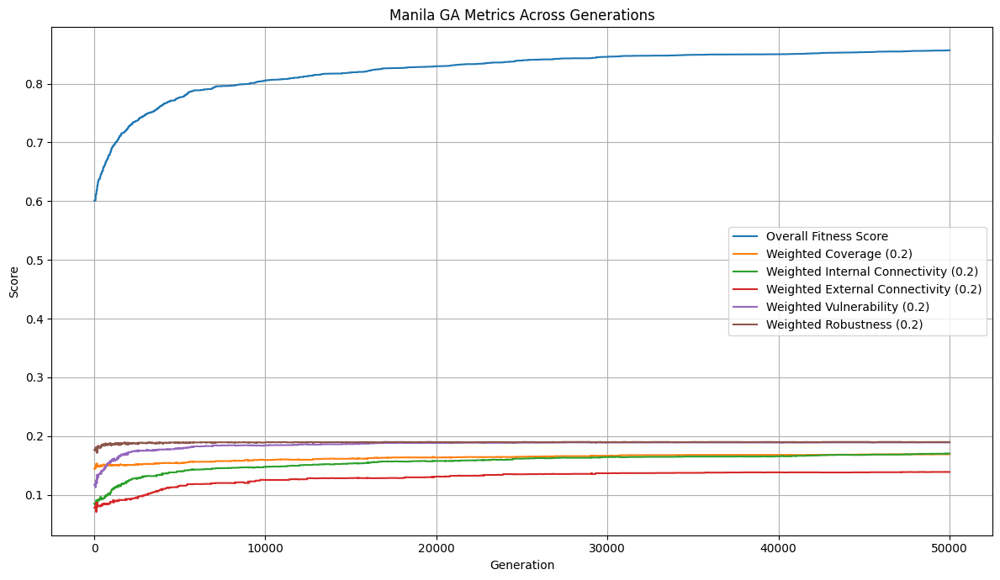

In [54]:
plot_ga_run_all_metrics_save(
    max_score_list,
    w_cov,
    w_int,
    w_ext,
    w_vul,
    w_rob,
    "Manila GA Metrics Across Generations",
    f"{generation_png_location}Manila_GA_Generations_{run_tag}_S{SEED}.png"
)

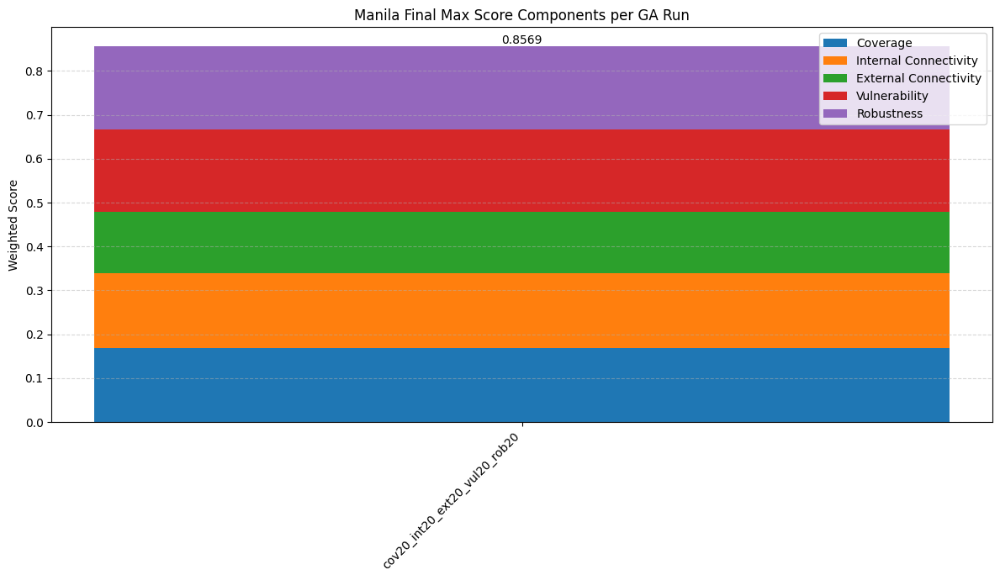

In [55]:
run_series = [
    {
        "label": run_tag,
        "max_score_list": max_score_list
    }
]

plot_ga_run_stacked_max_scores(
    run_series,
    "Manila Final Max Score Components per GA Run",
    f"{generation_png_location}Manila_GA_Stacked_Max_Scores_{run_tag}_S{SEED}.png"
)

In [ ]:
colors = [
    "Red", "Green", "Blue", "Orange", "Purple", "Cyan", "Magenta", "Maroon",
    "Olive", "Lime", "Teal", "Navy", "Aqua", "Fuchsia", "Coral", "Indigo",
    "Violet", "Brown", "DarkGreen", "DarkBlue", "DarkRed", "DarkCyan",
    "DarkMagenta", "DarkOrange", "DarkViolet", "DarkTurquoise", "DarkSlateGray",
    "SaddleBrown", "SeaGreen", "MidnightBlue", "ForestGreen", "Sienna",
    "SteelBlue", "RoyalBlue", "SlateBlue", "MediumSeaGreen", "MediumSlateBlue",
    "MediumPurple", "MediumTurquoise", "Crimson", "Goldenrod", "Chocolate",
    "FireBrick", "Peru", "RosyBrown", "IndianRed", "SlateGray", "DodgerBlue",
    "LightSeaGreen", "MediumAquamarine", "CadetBlue", "Turquoise"
] 

map_center = (14.599512, 120.984222)
m1 = folium.Map(location=map_center, zoom_start=10, tiles='openstreetmap') # "tiles='CartoDB Positron'" for black and white background
m2 = folium.Map(location=map_center, zoom_start=10, tiles='openstreetmap')

for route in population[0].routes:
    chosen_color = random.choice(colors)
    improved_route_plot(graph_of_stops_Manila, route, chosen_color, m1, route.route_id)
    
    index = population[0].routes.index(route)
    reversed_route = population[0].reversed_routes[index]
    if reversed_route != None:
        improved_route_plot(graph_of_stops_Manila, reversed_route, chosen_color, m2, reversed_route.route_id)

m1.save(f"{map_html_location}Manila_GA_Map_{run_tag}_S{SEED}.html")
m2.save(f"{map_html_location}Manila_GA_Map_Reverse_{run_tag}_S{SEED}.html")

#### Visualization of Transpo Stops in GA Results

In [ ]:
stops_map = plot_stops_on_map_graph(population[0].graph)
stops_map.save(f"{map_html_location}Manila_Stops_{run_tag}_S{SEED}.html") # Save the map to an HTML file

#### Export to CSV

In [ ]:
import csv

csv_path = f"{map_html_location}Manila_routes_{run_tag}_S{SEED}.csv"
with open(csv_path, mode='w', newline='') as file:
    writer = csv.writer(file)
    writer.writerow(['lat', 'long', 'route id'])
    
    for route in population[0].routes:
        for connection in route.route:
            if route.route.index(connection) == 0:
                lat = graph_of_stops_Manila.nodes[connection[0]]['y']
                long = graph_of_stops_Manila.nodes[connection[0]]['x']
                writer.writerow([lat, long, route.route_id])
            
            lat = graph_of_stops_Manila.nodes[connection[-1]]['y']
            long = graph_of_stops_Manila.nodes[connection[-1]]['x']
            writer.writerow([lat, long, route.route_id])

print("Data exported successfully.")

#### Summarized Metrics

In [ ]:
import networkx as nx
import numpy as np

def get_unique_route_stops(route_obj):
    stops = []
    for i, connection in enumerate(route_obj.route):
        if i == 0:
            stops.append(connection[0])
        stops.append(connection[-1])
    return stops

def get_route_stop_count(route_obj):
    return len(get_unique_route_stops(route_obj))

def get_route_lengths_km(network_obj):
    return [route.length for route in network_obj.routes if route is not None]

def average_degree(graph):
    degs = [d for _, d in graph.degree()]
    return sum(degs) / len(degs) if degs else 0

def graph_with_distance_weights(network_obj):
    G = nx.Graph()
    for u, v, data in network_obj.graph.edges(data=True):
        dist = data.get("distance", 1.0)
        if G.has_edge(u, v):
            if dist < G[u][v]["weight"]:
                G[u][v]["weight"] = dist
        else:
            G.add_edge(u, v, weight=dist)
    return G

def weighted_network_diameter_km(network_obj):
    G = graph_with_distance_weights(network_obj)
    if len(G) == 0:
        return 0
    if not nx.is_connected(G):
        largest_cc = max(nx.connected_components(G), key=len)
        G = G.subgraph(largest_cc).copy()
    lengths = dict(nx.all_pairs_dijkstra_path_length(G, weight="weight"))
    return max(max(d.values()) for d in lengths.values())

def avg_betweenness_centrality(network_obj):
    G = nx.Graph(network_obj.graph)
    if len(G) == 0:
        return 0
    bc = nx.betweenness_centrality(G, normalized=True)
    return sum(bc.values()) / len(bc) if bc else 0

def avg_closeness_centrality(network_obj):
    G = nx.Graph(network_obj.graph)
    if len(G) == 0:
        return 0
    cc = nx.closeness_centrality(G)
    return sum(cc.values()) / len(cc) if cc else 0

def summarize_network(network_obj):
    comp = network_obj.fitness_score_components
    route_lengths = get_route_lengths_km(network_obj)
    stop_counts = [get_route_stop_count(r) for r in network_obj.routes if r is not None]

    unique_stops = set()
    for r in network_obj.routes:
        if r is not None:
            unique_stops.update(get_unique_route_stops(r))

    summary = {
        "Coverage Score": comp["Coverage Raw"],
        "Internal Connectivity Score": comp["Internal Connectivity Raw"],
        "External Connectivity Score": comp["External Connectivity Raw"],
        "Vulnerability Score": comp["Vulnerability Raw"],
        "Robustness Score": comp["Robustness Raw"],
        "Total Fitness Score": network_obj.fitness_score,

        "Total Network Nodes": comp["Total Network Nodes"],
        "TotalRoutes": len([r for r in network_obj.routes if r is not None]),
        "TotalStops": len(unique_stops),

        "Shortest Route Length": min(route_lengths) if route_lengths else 0,
        "Longest Route Length": max(route_lengths) if route_lengths else 0,
        "Average Route Length": sum(route_lengths)/len(route_lengths) if route_lengths else 0,
        "Average Degree": average_degree(network_obj.graph),
        "Average Number of Stops per Route": sum(stop_counts)/len(stop_counts) if stop_counts else 0,
        "Network Diameter": weighted_network_diameter_km(network_obj),
        "Average Betweenness Centrality": avg_betweenness_centrality(network_obj),
        "Average Closeness Centrality": avg_closeness_centrality(network_obj),

        "n_i": comp["n_i"],
        "N_i": comp["N_i"],
        "r_i": comp["r_i"],
        "R_i": comp["R_i"],
        "Min Intersections Per Route": comp["Min Intersections Per Route"],

        "n_e": comp["n_e"],
        "N_e": comp["N_e"],
        "r_e": comp["r_e"],
        "R_e": comp["R_e"],
        "Min Transpo Stops Per Route": comp["Min Transpo Stops Per Route"],

        "Target Node Ratio": comp["Target Node Ratio"],
        "Total Potential Transport Nodes": comp["Total Potential Transport Nodes"],

        "q_c Vulnerability": comp["q_c Vulnerability"],
        "q_c Robustness": comp["q_c Robustness"],
    }
    return summary

In [ ]:
best_network = population[0]
optimized_summary = summarize_network(best_network)

for k, v in optimized_summary.items():
    if isinstance(v, float):
        if "Length" in k or "Diameter" in k:
            print(f"{k}: {v:.4f} km")
        else:
            print(f"{k}: {v:.4f}")
    else:
        print(f"{k}: {v}")

In [ ]:
metric_ranges = metric_ranges_for_network()

print("\n--- Possible Metric Ranges for Final GA Network ---")
for metric, (low, high) in metric_ranges.items():
    print(f"{metric}: {low:.4f} to {high:.4f}")